[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LRCole3/pre-training-pathway/blob/main/10_capstone_unified_pretraining.ipynb)

# 10 · Capstone: One Backbone, Three Pretraining Objectives, Two Kinds of Data

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Counting and embeddings | Count n-grams; learn word vectors | A first language model; similar words get similar vectors | Fixed window; one vector per word |
| 02 | RNNs, attention, ELMo | Carry a state; look back with attention; reuse the pretrained network | Context beyond a window; contextual features | Memory fades with distance; no parallel training |
| 03 | The transformer | Attention only, then today's block (RoPE, RMSNorm, SwiGLU, GQA, MoE) | Direct access to any earlier token; parallel training | Needs an objective and a transfer recipe |
| 04 | Objectives and transfer | Causal, masked and span-corruption pretraining | Representations that transfer with few labels | No objective wins everything; optimisation untested |
| 05 | Making it scale | Tokenisers, the optimiser recipe, scaling laws | A recipe that keeps improving with size | Discrete tokens only |
| 06 | VAE, GAN, pixel models | Generative models for images before diffusion | Sampling images at all | Blur, mode collapse, slow sampling |
| 07 | Diffusion design space | Denoise step by step; schedule, target, weighting | Quality and coverage together | Pixel space, MLP backbone, no text |
| 08 | Encoders, CLIP, latent diffusion | Pretrain the parts: vision encoder, text-image model, autoencoder | Conditioning and compression | The backbone still does not scale |
| 09 | Diffusion transformers | Patch tokens, flow matching, training accelerators | A scalable denoiser | Base models still need post-training |
| **10** | **Capstone** | **One backbone, three objectives, two modalities** | **A unified view of pretraining** | **The post-training series starts here** |

Nine notebooks built pretraining piece by piece. Notebooks 01 to 05 trained language models, almost always by
predicting the next token. Notebooks 06 to 09 trained image generators, and ended with diffusion. In between we met a
third objective twice: hide part of the input and predict it (BERT in notebook 04, the masked autoencoder in
notebook 08).

By notebook 09 the network was the same in both halves of the series: a transformer over tokens. What still differs
between a language model and an image generator is the **objective**. This notebook holds everything else fixed and
changes only that:

* **one backbone**: three transformer blocks of width 64, about 250,000 parameters, one training recipe;
* **three objectives**: autoregressive, masked diffusion, Gaussian diffusion;
* **two kinds of data**: the 8×8 digits and the synthetic language of this series.

That gives six models. For each we measure sample quality, sampling cost, memorisation and the usefulness of the
hidden states as features. The questions are the ones the field has been asking since 2021: why are language models
autoregressive and image generators diffusion models, and what happens when you cross them
(image generation from tokens: [Esser et al., 2020](https://arxiv.org/abs/2012.09841), [Chang et al., 2022](https://arxiv.org/abs/2202.04200), [Tian et al., 2024](https://arxiv.org/abs/2404.02905); diffusion for text: [Austin et al., 2021](https://arxiv.org/abs/2107.03006),
[Li et al., 2022](https://arxiv.org/abs/2205.14217), [Sahoo et al., 2024](https://arxiv.org/abs/2406.07524), [Nie et al., 2025](https://arxiv.org/abs/2502.09992))?

The notebook closes the series: a scorecard over all ten notebooks, a table of the design choices we tested, the
recipes of well-known pretrained models, and the hand-off to the
[post-training series](https://github.com/LRCole3/post-training-pathway).

## Learning objectives

1. Describe the three objectives as three ways to corrupt data and reconstruct it, and write each loss.
2. Train one transformer backbone with each objective, on tokens and on continuous vectors.
3. Compare the objectives on sample quality, sampling cost, memorisation and representation quality, and say which
   differences come from the objective and which from the data.
4. Place well-known pretrained models (BERT, GPT, Llama, CLIP, MAE, Stable Diffusion, DiT, MaskGIT, LLaDA) in one
   table of objective, architecture and design choices.

**Runtime:** 27 to 30 minutes on a laptop CPU. Nine models are trained: three image models (under a minute each)
and six language models (three to five minutes each).

In [1]:
# Setup. Locally this only adds the repo to the path. In Colab it first clones the repository (untested path).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("prelib"):
    os.system("git clone -q https://github.com/LRCole3/pre-training-pathway.git"); os.chdir("pre-training-pathway")
sys.path.insert(0, ".")

import time, math, os, copy, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from prelib import unified as U, diffusion as D, vision as V, world as W, objectives as O, images, metrics, viz, set_seed
viz.style()
torch.set_num_threads(min(4, torch.get_num_threads()))
pd.set_option("display.width", 240); pd.set_option("display.max_columns", 24); pd.set_option("display.max_colwidth", 60)

# images: 8x8 digits, the frozen judge and the scorecard of notebooks 06 to 09
Xtr, ytr, Xte, yte = images.load_digits_tensor()
judge = images.get_judge()
card = metrics.ImageScorecard(judge, Xtr, Xte, yte)
N = len(Xte)
LABELS = ytr[torch.randperm(len(ytr), generator=torch.Generator().manual_seed(0))[:N]]     # the digits we ask for
REAL = card.real_baseline(); card.rows.pop()

# language: the synthetic documents of notebooks 01 to 05
TR_L, TE_L = torch.as_tensor(W.corpus("train")["tokens"]), torch.as_tensor(W.corpus("test")["tokens"])
NO_LABEL = torch.zeros(len(TR_L), dtype=torch.long)
FORBID = (W.PAD, W.BOS, W.MASK)                       # tokens a sampler may not produce
FLOOR = W.floor()                                     # loss of the best possible predictor, nats per token

STEPS_I, STEPS_L = 1500, 3000                         # training steps for image models and for language models
print(f"images: {len(Xtr)} train / {N} held out   documents: {len(TR_L)} train / {len(TE_L)} held out   floor {FLOOR:.4f} nats per token")

images: 1438 train / 359 held out   documents: 20000 train / 2000 held out   floor 2.4704 nats per token


## 1. Three ways to hide data

Every objective in this series can be read as: **corrupt the data, then train a network to undo the corruption**.
The three differ in what the corruption is.

**Autoregressive.** Hide everything after position $i$ and predict token $i$. Doing this for every $i$ gives the exact
log-likelihood:

$$-\log p_\theta(x) = -\sum_{i=1}^{n} \log p_\theta(x_i \mid x_{<i}).$$

Sampling undoes the corruption one token at a time, so it costs $n$ network evaluations.

**Masked diffusion.** Draw a share $r$ uniformly between 0 and 1, replace each token by a `[mask]` token with
probability $r$, and predict the hidden tokens from the visible ones. With the weight $1/r$ the loss is an upper
bound on the negative log-likelihood ([Austin et al., 2021](https://arxiv.org/abs/2107.03006), [Sahoo et al., 2024](https://arxiv.org/abs/2406.07524)):

$$-\log p_\theta(x) \;\le\; \mathbb{E}_{r \sim U(0,1)}\; \frac{1}{r} \sum_{i\,:\,x_i \text{ hidden}} -\log p_\theta(x_i \mid x_\text{visible}).$$

BERT (notebook 04) is this loss at one fixed share, 15%. Drawing the share anew for every example is what turns a
representation learner into a generator: the network has seen every amount of masking between "nearly all visible"
and "nothing visible", so sampling can start from a fully masked sequence and reveal tokens in any number of rounds.

**Gaussian diffusion.** Add noise to every value, and predict the clean data (notebook 07):

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon, \qquad \epsilon \sim \mathcal{N}(0, I).$$

Pixels are numbers, so this applies to images directly. Tokens are not numbers. To use it on text, each token is
first replaced by a vector, and the network is asked which token each noisy vector was ([Li et al., 2022](https://arxiv.org/abs/2205.14217),
[Dieleman et al., 2022](https://arxiv.org/abs/2211.15089)). Our version is a simplified one: the vectors are fixed random vectors of 16 numbers and the loss
is the cross-entropy of the token.

The figure shows the three corruptions at the same strength, on one digit and on the first 32 tokens of one
document. Grey means hidden. In the last row nothing is hidden and everything is perturbed: the digit is noisy, and
a word outlined in red is one whose noisy vector is now closer to a different word.

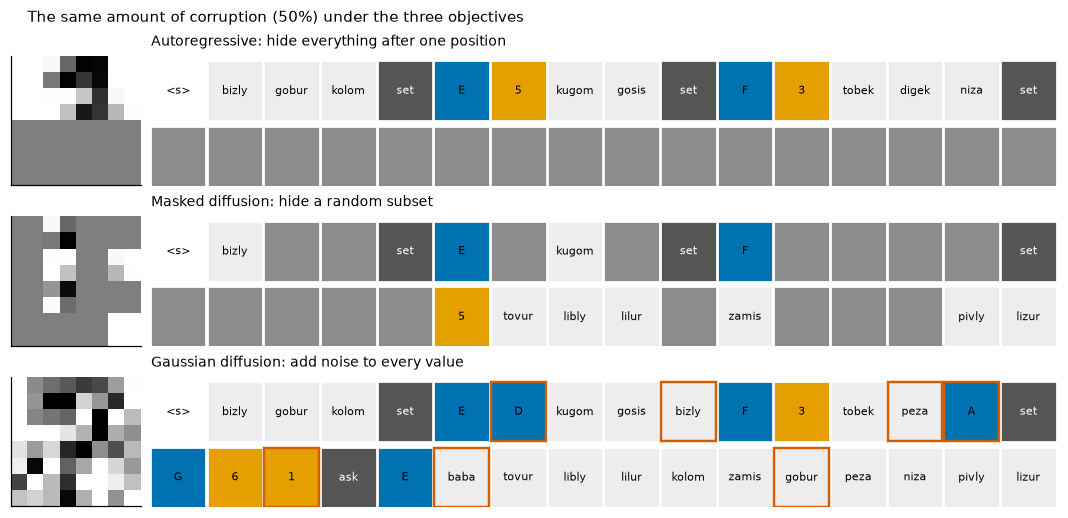

In [2]:
POS2 = U.sincos_2d(4, 64)                             # positions of the 16 image tokens (4 x 4 grid), as in notebook 09
tok = U.PatchTokenizer(Xtr, 256)                      # image -> 16 tokens (section 3 looks at this tokenizer)
TOK_TR, TOK_TE = tok.encode(Xtr), tok.encode(Xte)
EMB = U.EmbeddingDiffusion(W.VOCAB)                   # Gaussian diffusion for word tokens
GAUSS = D.Diffusion(schedule="cosine", pred="x0", weighting="min-snr")     # Gaussian diffusion for pixels (notebook 07)
HIDDEN = "#8C8C8C"
TITLES = {"future": "Autoregressive: hide everything after one position", "subset": "Masked diffusion: hide a random subset",
          "noise": "Gaussian diffusion: add noise to every value"}

def show_corruptions(amount=0.5, digit=3, seed=0):
    g = torch.Generator().manual_seed(seed)
    x, toks, doc = Xte[digit:digit + 1], TOK_TE[digit], TE_L[5, :32]
    t = torch.tensor([min(999, int(amount * 1000))])
    fig = plt.figure(figsize=(9.6, 4.6)); gs = fig.add_gridspec(3, 2, width_ratios=[1, 7])
    for r, kind in enumerate(TITLES):
        axd, axt = fig.add_subplot(gs[r, 0]), fig.add_subplot(gs[r, 1])
        if kind == "noise":
            img = GAUSS.q_sample(x, t, torch.randn(x.shape, generator=g))[0]
            dist = torch.cdist(EMB.noised(doc[None], t, g)[0], EMB.E); dist[:, list(FORBID)] = float("inf")
            near = dist.argmin(-1); near[0] = doc[0]                # the word whose vector is now the closest
            words, colors = [W.WORDS[int(i)] for i in near], viz.doc_colors(near)
            edge = [viz.VERMILION if int(a) != int(b) else None for a, b in zip(near, doc)]
        else:
            if kind == "future":
                hide_i, hide_t = torch.arange(16) >= round((1 - amount) * 16), torch.arange(32) >= max(1, round((1 - amount) * 32))
            else:
                hide_i, hide_t = torch.rand(16, generator=g) < amount, torch.rand(32, generator=g) < amount
            hide_t[0] = False                                      # the start token is always given
            p = U.patchify(tok.decode(toks[None]), 2); p[0, hide_i] = 0.0; img = U.unpatchify(p, 2)[0]
            words = ["" if h else W.WORDS[int(i)] for i, h in zip(doc, hide_t)]
            colors = [HIDDEN if h else c for c, h in zip(viz.doc_colors(doc), hide_t)]; edge = None
        axd.imshow(img.view(8, 8), cmap="gray_r", vmin=-1, vmax=1); axd.set_xticks([]); axd.set_yticks([])
        viz.token_strip(axt, words, colors=colors, wrap=16, fontsize=7, edge=edge)
        axt.set_title(TITLES[kind], fontsize=9)
    fig.suptitle(f"The same amount of corruption ({amount:.0%}) under the three objectives", fontsize=10, x=0.02, ha="left")
    plt.show()

show_corruptions(0.5)

**Explorer.** Move the slider to change how much is corrupted, and pick another digit. At 0% the three rows are the
data; at 100% the first two rows are fully hidden and the third is pure noise. Every sampler in this notebook walks
from the right end of this slider to the left end.

Static preview at the default settings {'amount': 0.75, 'digit': 3}. Run the notebook to get the controls.


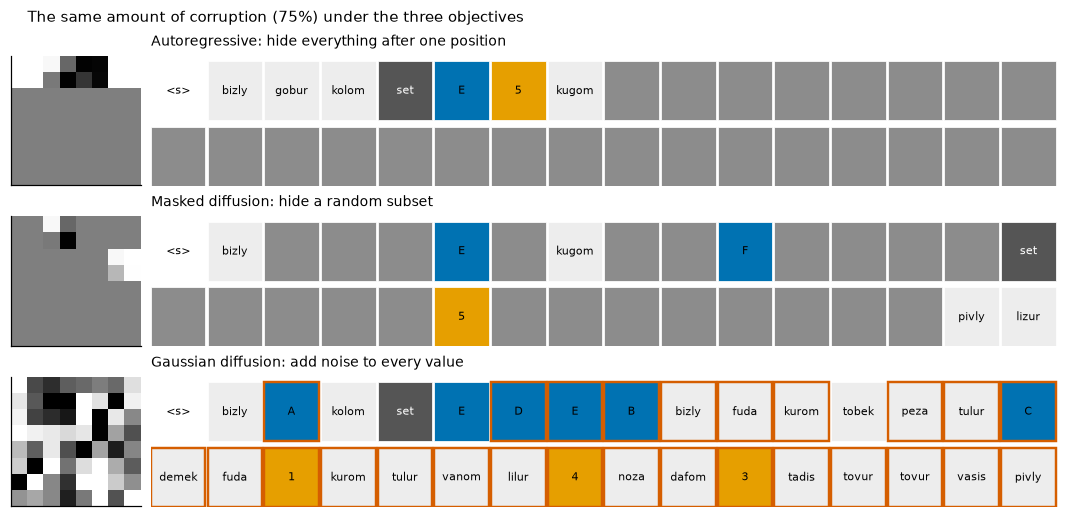

In [3]:
viz.explore(lambda amount, digit: show_corruptions(amount, digit), amount=(0.0, 1.0, 0.05, 0.75), digit=(0, 30, 1, 3))

## 2. One backbone

All six models share `prelib.unified.Backbone`: three pre-norm transformer blocks of width 64 with four attention
heads. A condition vector (the class label for images, the timestep for Gaussian diffusion) enters every block
through adaLN-Zero, the route that won in notebook 09. The backbone does not know what its tokens are. Around it
sit two thin adapters:

* `Discrete`: token ids go through an embedding table, and a linear layer returns a score for every token of the
  vocabulary. With `causal=True` the input is shifted one place to the right and attention may only look back:
  an autoregressive model. With `causal=False` attention sees the whole sequence, and some inputs are the `[mask]`
  token: a masked model.
* `Continuous`: vectors go through a linear layer, and a linear layer returns vectors (clean patches) or scores
  (which word). It is told the timestep: a denoiser.

The only other difference between the image models and the language models is the position scheme. The 16 image
tokens get the fixed two-dimensional sinusoidal vectors that were best in notebook 09. The 64 word tokens get rotary
positions (RoPE, [Su et al., 2021](https://arxiv.org/abs/2104.09864); notebook 03). Section 8 shows why that choice matters here.

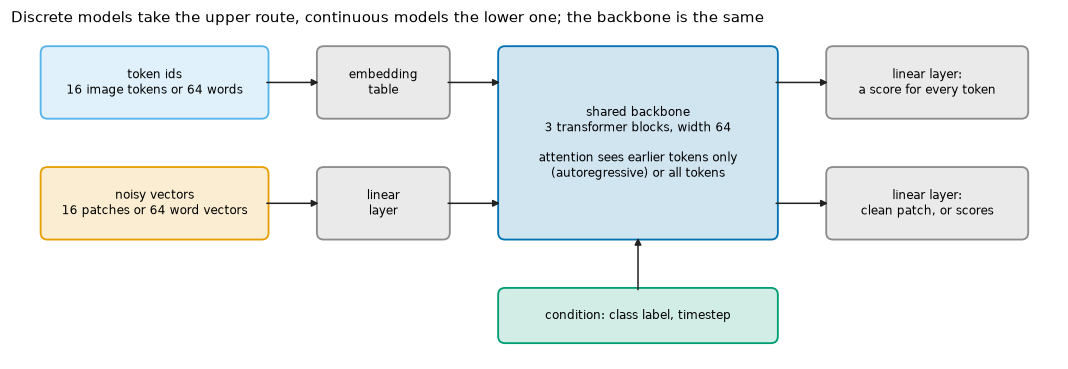

input       attention           predicts  parameters  backbone
data     objective                                                                                                          
images   autoregressive                    16 tokens, shifted right  earlier tokens        every token      266240    232384
         masked diffusion        16 tokens, some replaced by [mask]      all tokens  the hidden tokens      266240    232384
         Gaussian diffusion       16 noisy patches and the timestep      all tokens  the clean patches      246084    232384
language autoregressive                    64 tokens, shifted right  earlier tokens        every token      242961    232384
         masked diffusion        64 tokens, some replaced by [mask]      all tokens  the hidden tokens      242961    232384
         Gaussian diffusion  64 noisy word vectors and the timestep      all tokens        every token      251153    232384

In [4]:
fig, ax = plt.subplots(figsize=(9.6, 3.3))
viz.diagram(ax, [
    (0.0, 1.7, 2.6, 0.8, "token ids\n16 image tokens or 64 words", viz.SKY),
    (0.0, 0.3, 2.6, 0.8, "noisy vectors\n16 patches or 64 word vectors", viz.ORANGE),
    (3.2, 1.7, 1.5, 0.8, "embedding\ntable", viz.GREY), (3.2, 0.3, 1.5, 0.8, "linear\nlayer", viz.GREY),
    (5.3, 0.3, 3.2, 2.2, "shared backbone\n3 transformer blocks, width 64\n\nattention sees earlier tokens only\n(autoregressive) or all tokens", viz.BLUE),
    (9.1, 1.7, 2.3, 0.8, "linear layer:\na score for every token", viz.GREY), (9.1, 0.3, 2.3, 0.8, "linear layer:\nclean patch, or scores", viz.GREY),
    (5.3, -0.9, 3.2, 0.6, "condition: class label, timestep", viz.GREEN)],
    [(2.6, 2.1, 3.2, 2.1), (2.6, 0.7, 3.2, 0.7), (4.7, 2.1, 5.3, 2.1), (4.7, 0.7, 5.3, 0.7), (8.5, 2.1, 9.1, 2.1), (8.5, 0.7, 9.1, 0.7),
     (6.9, -0.3, 6.9, 0.3)], fontsize=8)
ax.set_title("Discrete models take the upper route, continuous models the lower one; the backbone is the same")
plt.show()

ROT = U.Rotary(W.DOC_LEN)                              # rotary positions for the 64 word tokens
spec = [("images", "autoregressive", U.Discrete(256, POS2, causal=True, n_classes=11), "16 tokens, shifted right", "earlier tokens", "every token"),
        ("images", "masked diffusion", U.Discrete(256, POS2, causal=False, n_classes=11), "16 tokens, some replaced by [mask]", "all tokens", "the hidden tokens"),
        ("images", "Gaussian diffusion", U.PatchDenoiser(), "16 noisy patches and the timestep", "all tokens", "the clean patches"),
        ("language", "autoregressive", U.Discrete(W.VOCAB, ROT, causal=True), "64 tokens, shifted right", "earlier tokens", "every token"),
        ("language", "masked diffusion", U.Discrete(W.VOCAB, ROT, causal=False), "64 tokens, some replaced by [mask]", "all tokens", "the hidden tokens"),
        ("language", "Gaussian diffusion", U.Continuous(EMB.dim, W.VOCAB, ROT), "64 noisy word vectors and the timestep", "all tokens", "every token")]
backbone_of = lambda m: (m.net if hasattr(m, "net") else m).backbone
display(pd.DataFrame([dict(data=d, objective=o, input=i, attention=a, predicts=p, parameters=U.n_params(m),
                           backbone=U.n_params(backbone_of(m))) for d, o, m, i, a, p in spec]).set_index(["data", "objective"]))

**What to read off.** The backbone has 232,384 parameters in all six models. The adapters add between 10,000 and
34,000, so the totals run from 242,961 to 266,240. Differences between the models below are not differences of
capacity.

## 3. Images as tokens

Two of the three objectives need discrete tokens. Notebook 08 learned a quantised autoencoder for this
(VQ-VAE, [Oord et al., 2017](https://arxiv.org/abs/1711.00937)). Here we use the simplest tokenizer that works: cut the image into its sixteen 2×2 patches
and replace each patch by the index of its nearest entry in a codebook of $k$ patches, found by k-means on the
training patches. An image becomes 16 integers.

A tokenizer puts a ceiling on every model trained on its tokens: no sample can be better than a real image that has
been encoded and decoded. The cell measures that ceiling for several codebook sizes by scoring the reconstructions
of the held-out images as if they were samples.

,fd,judge_acc,squared_error,bits_per_image
codebook,,,,
32,6.39,0.98,2.22,80.0
64,2.57,0.96,1.43,96.0
128,1.32,0.98,0.90,112.0
256,0.48,0.97,0.61,128.0
512,0.21,0.97,0.39,144.0


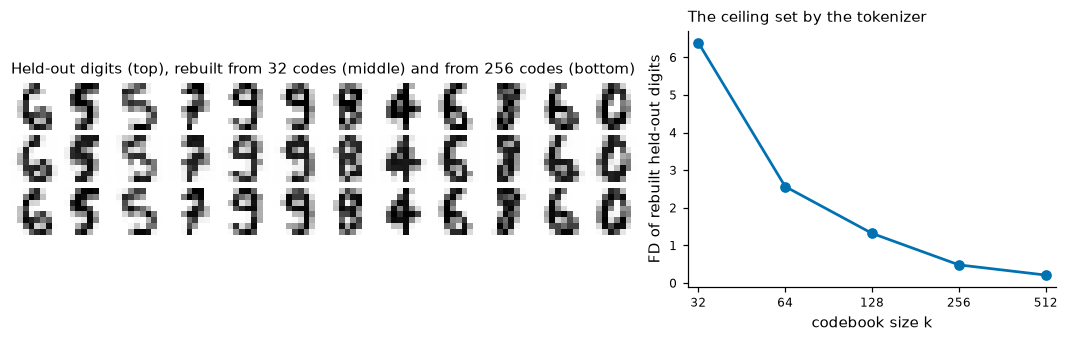

In [5]:
ceil, recon = [], {}
for k in (32, 64, 128, 256, 512):
    tk = tok if k == 256 else U.PatchTokenizer(Xtr, k)
    recon[k] = tk.decode(tk.encode(Xte))
    row = card.evaluate(recon[k], f"k = {k}", labels=yte); card.rows.pop()
    ceil.append(dict(codebook=k, fd=row["fd"], judge_acc=row["judge_acc"], squared_error=float(((recon[k] - Xte) ** 2).sum(1).mean()),
                     bits_per_image=16 * math.log2(k)))
ceil = pd.DataFrame(ceil).set_index("codebook")
display(ceil.round(2))

fig = plt.figure(figsize=(9.6, 3.0)); gs = fig.add_gridspec(1, 2, width_ratios=[1.7, 1])
ax = fig.add_subplot(gs[0])
images.show_grid(torch.cat([Xte[:12], recon[32][:12], recon[256][:12]]), nrow=12, ax=ax)
ax.set_title("Held-out digits (top), rebuilt from 32 codes (middle) and from 256 codes (bottom)")
ax = fig.add_subplot(gs[1])
ax.plot(ceil.index, ceil.fd, "o-", color=viz.BLUE)
ax.set_xscale("log", base=2); ax.set_xticks(ceil.index); ax.set_xticklabels(ceil.index)
ax.set_xlabel("codebook size k"); ax.set_ylabel("FD of rebuilt held-out digits"); ax.set_title("The ceiling set by the tokenizer")
plt.show()

**What happened.** The ceiling falls quickly with the codebook size: FD 6.4 with 32 codes, 2.6 with 64, 1.3 with
128, 0.5 with 256 and 0.2 with 512. For scale, real training images score 5.4 against the held-out images. We use
256 codes: the tokenizer then costs half a point of FD, and an image is 16 tokens of 8 bits each.

Keep one number in mind for section 5. The training set is 1,438 images, which is 23,008 tokens, and each of them is
a choice among 256 codes.

## 4. Three objectives on images

Now the experiment. The three image models share the backbone, the optimiser, the batch size (128), the number of
steps (1,500) and the label conditioning with 10% label dropout. They differ in the objective and in the adapter it
needs:

| | Input | Loss | Sampler |
|---|---|---|---|
| Autoregressive | 16 tokens | cross-entropy of every token given the earlier ones | one token per network evaluation: 16 evaluations |
| Masked diffusion | 16 tokens, a random share masked | cross-entropy of the hidden tokens, weighted by 1 / share | reveal the tokens in a chosen number of rounds: 1 to 16 evaluations |
| Gaussian diffusion | 16 noisy patches | squared error to the clean patches, min-SNR weight (notebook 07) | deterministic DDIM steps: any number of evaluations |

The third row is the base diffusion transformer of notebook 09, rebuilt on the shared backbone.

While each model trains we stop every 100 steps to measure three things on the averaged weights: its loss on
training images and on held-out images, the FD of its samples, and how close its samples are to the training set.
Section 5 uses these curves. `score` adds two memorisation columns to the scorecard of notebooks 06 to 09:

* `dist_train`: the median distance from a sample to its nearest training image;
* `copies`: the share of samples whose 16 tokens are exactly the 16 tokens of some training image.

In [6]:
TRAIN_SET = {tuple(r) for r in TOK_TR.tolist()}

def score(x, name, nfe):
    # the scorecard of notebooks 06-09, plus two memorisation columns
    row = card.evaluate(x, name, nfe=nfe, labels=LABELS); card.rows.pop()
    row["dist_train"] = float(torch.cdist(x.clamp(-1, 1), Xtr).min(1).values.median())
    row["copies"] = float(np.mean([tuple(r) in TRAIN_SET for r in tok.encode(x.clamp(-1, 1)).tolist()]))
    return row

def nll_ar(model, toks, labels):
    with torch.no_grad():
        return float(F.cross_entropy(model(toks, labels).reshape(-1, model.vocab), toks.reshape(-1)))

def sample_images(kind, model, steps=None, order="random", seed=0, labels=None):
    labels = LABELS if labels is None else labels
    if kind == "autoregressive":
        return tok.decode(U.sample_ar(model, len(labels), 16, labels, seed=seed))
    if kind == "masked":
        return tok.decode(U.sample_masked(model, len(labels), 16, steps or 8, labels, seed=seed, order=order))
    return GAUSS.sample(model, labels, steps=steps or 50, seed=seed)

NFE = {"autoregressive": 16, "masked": 8, "diffusion": 50}       # network evaluations per image of the default sampler

def train_image(kind, steps=STEPS_I, seed=0):
    set_seed(seed)
    if kind == "autoregressive":
        net, obj, data = U.Discrete(256, POS2, causal=True, n_classes=11), U.Autoregressive(), TOK_TR
    elif kind == "masked":
        net, obj, data = U.Discrete(256, POS2, causal=False, n_classes=11), U.MaskedDiffusion(), TOK_TR
    else:
        net, obj, data = U.PatchDenoiser(), GAUSS, Xtr
    log, snaps = [], {}
    def measure(step, raw, ema):
        if kind == "autoregressive":                               # nats per token, exact
            a, b = nll_ar(ema, TOK_TR[:N], ytr[:N]), nll_ar(ema, TOK_TE, yte)
        elif kind == "masked":                                     # nats per token, upper bound
            a, b = obj.bound(ema, TOK_TR[:N], ytr[:N], repeats=4), obj.bound(ema, TOK_TE, yte, repeats=4)
        else:                                                      # squared error of the estimate of the clean image
            a, b = (float(np.mean(obj.error_by_time(ema, X, y, bins=5, repeats=2)[1])) for X, y in ((Xtr[:N], ytr[:N]), (Xte, yte)))
        r = score(sample_images(kind, ema), kind, NFE[kind])
        log.append(dict(step=step, train=a, heldout=b, fd=r["fd"], dist_train=r["dist_train"], copies=r["copies"], judge_acc=r["judge_acc"]))
        snaps[step] = copy.deepcopy(ema.state_dict())
    out = D.train(net, obj, data, ytr, steps=steps, seed=seed, callback=measure, every=100)
    out.update(kind=kind, obj=obj, log=pd.DataFrame(log).set_index("step"), snaps=snaps, params=U.n_params(net))
    print(f"{kind:15s} {out['params']:,} parameters, {steps} steps, {out['seconds']:.0f} s (including the measurements every 100 steps)")
    return out

IMG = {kind: train_image(kind) for kind in ("autoregressive", "masked", "diffusion")}

autoregressive  266,240 parameters, 1500 steps, 38 s (including the measurements every 100 steps)
masked          266,240 parameters, 1500 steps, 42 s (including the measurements every 100 steps)
diffusion       246,084 parameters, 1500 steps, 48 s (including the measurements every 100 steps)


,fd,precision,coverage,judge_acc,nfe,dist_train,copies,params,train_seconds
model,,,,,,,,,
real held-out images,5.35,0.96,0.96,0.98,0,2.07,0.00,NaN,NaN
autoregressive over tokens,5.23,0.94,0.95,0.94,16,0.75,0.87,266240.0,38.36
"masked diffusion over tokens, 8 rounds",8.43,0.87,0.80,0.95,8,2.79,0.00,266240.0,41.95
"Gaussian diffusion over patches, 50 steps",6.89,0.91,0.89,0.95,50,2.42,0.00,246084.0,48.10


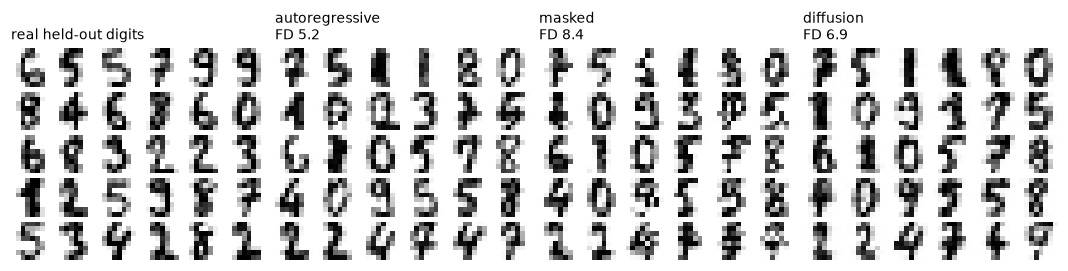

In [7]:
ROWS_I, SAMPLES = {}, {}
names_i = {"autoregressive": "autoregressive over tokens", "masked": "masked diffusion over tokens, 8 rounds", "diffusion": "Gaussian diffusion over patches, 50 steps"}
for kind, name in names_i.items():
    SAMPLES[kind] = sample_images(kind, IMG[kind]["model"])
    ROWS_I[name] = dict(score(SAMPLES[kind], name, NFE[kind]), params=IMG[kind]["params"], train_seconds=IMG[kind]["seconds"])
held = dict(REAL, model="real held-out images", dist_train=float(torch.cdist(Xte, Xtr).min(1).values.median()),
            copies=float(np.mean([tuple(r) in TRAIN_SET for r in TOK_TE.tolist()])))
cols = ["fd", "precision", "coverage", "judge_acc", "nfe", "dist_train", "copies", "params", "train_seconds"]
t_img = pd.DataFrame([held] + list(ROWS_I.values())).set_index("model")[cols]
display(t_img.round(2))

fig, axes = plt.subplots(1, 4, figsize=(9.6, 3.1))
for ax, (title, x) in zip(axes, [("real held-out digits", Xte[:30])] + [(k, SAMPLES[k][:30]) for k in names_i]):
    images.show_grid(x, nrow=6, ax=ax); ax.set_title(title if title.startswith("real") else f"{title}\nFD {ROWS_I[names_i[title]]['fd']:.1f}", fontsize=9)
plt.show()

**What happened.** By the scorecard of notebooks 06 to 09 the autoregressive model wins, and by a margin that
should raise suspicion: its FD of 5.2 is as good as that of real data (5.4), with precision 0.94 and coverage 0.95.
Gaussian diffusion follows at 6.9 and masked diffusion at 8.4 with 8 network evaluations.

The two memorisation columns explain the first row.

* `copies`: 87% of the autoregressive model's samples are, token for token, an image of the training set. The share
  is 0% for the other two models, and 0% for the held-out images themselves.
* `dist_train`: the autoregressive samples sit at a median distance of 0.75 from their nearest training image. A
  real image that the model has never seen sits at 2.07. The masked and Gaussian models are at 2.79 and 2.42.

The Gaussian model's 6.9 is close to the 6.4 to 6.6 that the same configuration reached in notebook 09 (sinusoidal
positions, 1,500 steps), so the shared backbone has not cost it anything.

## 5. Before believing a low FD: is the model copying?

Every notebook since 06 has checked a good score for memorisation before reporting it. The `copies` column of the
table above says the check is needed here. The curves recorded during training show what happened.

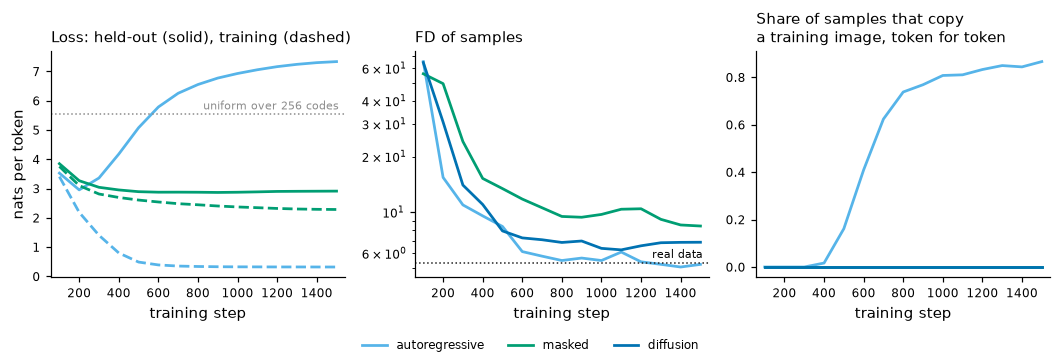

,train,heldout,fd,dist_train,copies,judge_acc
step,,,,,,
100,3.41,3.53,65.26,5.04,0.00,0.15
200,2.19,2.96,15.43,3.67,0.00,0.62
300,1.40,3.36,10.96,3.26,0.00,0.73
400,0.80,4.18,9.56,2.92,0.02,0.80
600,0.39,5.79,6.13,1.56,0.41,0.89
800,0.34,6.55,5.49,0.78,0.74,0.94
1000,0.33,6.93,5.49,0.76,0.81,0.96
1500,0.32,7.34,5.23,0.75,0.87,0.94


autoregressive model: lowest held-out loss at step 200


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.2))
col = {"autoregressive": viz.SKY, "masked": viz.GREEN, "diffusion": viz.BLUE}
ax = axes[0]
for kind in ("autoregressive", "masked"):
    lg = IMG[kind]["log"]
    ax.plot(lg.index, lg.heldout, color=col[kind]); ax.plot(lg.index, lg.train, color=col[kind], ls="--")
ax.axhline(math.log(256), color=viz.GREY, lw=1, ls=":")
ax.annotate("uniform over 256 codes", (0.98, math.log(256)), xycoords=("axes fraction", "data"), xytext=(0, 3), textcoords="offset points", ha="right", fontsize=7, color=viz.GREY)
ax.set_xlabel("training step"); ax.set_ylabel("nats per token"); ax.set_title("Loss: held-out (solid), training (dashed)")
for ax, key, title, ref in ((axes[1], "fd", "FD of samples", REAL["fd"]), (axes[2], "copies", "Share of samples that copy\na training image, token for token", None)):
    for kind in col:
        ax.plot(IMG[kind]["log"].index, IMG[kind]["log"][key], color=col[kind], label=kind)
    if ref is not None:
        ax.axhline(ref, color=viz.BLACK, lw=1, ls=":")
        ax.annotate("real data", (0.98, ref), xycoords=("axes fraction", "data"), xytext=(0, 3), textcoords="offset points", ha="right", fontsize=7)
        ax.set_yscale("log")
    ax.set_xlabel("training step"); ax.set_title(title)
fig.legend(*axes[2].get_legend_handles_labels(), loc="outside lower center", ncol=3, fontsize=8)
plt.show()

best = int(IMG["autoregressive"]["log"].heldout.idxmin())
display(IMG["autoregressive"]["log"].loc[[s for s in (100, 200, 300, 400, 600, 800, 1000, 1500) if s in IMG["autoregressive"]["log"].index]].round(2))
print(f"autoregressive model: lowest held-out loss at step {best}")

**What happened.**

* **The autoregressive model memorised the training set.** Its loss on training images falls to 0.32 nats per token.
  Its loss on held-out images is lowest at step 200 (2.96) and then rises to 7.34. Guessing uniformly among the 256
  codes costs 5.55, so after step 600 the model is worse on new images than a model that knows nothing.
* **FD rewards this.** The FD of its samples improves throughout: 15.4 at step 200, 6.1 at step 600, 5.2 at the
  end. Copies of training images are excellent digits. The share of copies is 0% up to step 300, 2% at step 400,
  41% at step 600 and 87% at step 1,500.
* **The masked model did not memorise**, with the same tokens, the same backbone and the same number of steps. Its
  bound is 2.24 on training images and 2.84 on held-out images at the end, and none of its samples is a copy. In
  likelihood terms it is also the better model of the two: its *bound* on held-out images (2.84) is below the best
  *exact* loss the autoregressive model ever reaches (2.96).
* **The Gaussian model** produced no copies either.

Why would the objective matter this much? A reading that the notebook does not test: the autoregressive objective
shows each training image in exactly one way. Every pass over the data poses the same 23,008 prediction problems,
and 1,500 steps of batch 128 are 133 passes, for a model with 266,240 parameters. The masked objective hides a new
random subset every time (there are 65,536 subsets of 16 tokens), and Gaussian diffusion draws new noise every time.
Both act as data augmentation built into the objective. Diffusion models do memorise when the data is small enough
relative to the model ([Carlini et al., 2023](https://arxiv.org/abs/2301.13188), [Kadkhodaie et al., 2023](https://arxiv.org/abs/2310.02557)); the MLP denoiser of notebook 07 showed the first signs.

The autoregressive row of the table is therefore not a fair entry. The next cell restores two earlier sets of
weights and scores their samples:

* the model **stopped where its held-out loss is lowest**, the standard rule;
* the model at the **last measurement with fewer than 5% copies**, a rule that looks at the samples and so favours
  the model as far as it honestly can.

It then puts samples next to their nearest training image.

,fd,precision,coverage,judge_acc,nfe,dist_train,copies,params,train_seconds
model,,,,,,,,,
real held-out images,5.35,0.96,0.96,0.98,0,2.07,0.00,NaN,NaN
autoregressive over tokens,5.23,0.94,0.95,0.94,16,0.75,0.87,266240.0,38.36
"masked diffusion over tokens, 8 rounds",8.43,0.87,0.80,0.95,8,2.79,0.00,266240.0,41.95
"Gaussian diffusion over patches, 50 steps",6.89,0.91,0.89,0.95,50,2.42,0.00,246084.0,48.10
"autoregressive over tokens, stopped at step 200",15.43,0.70,0.59,0.62,16,3.67,0.00,266240.0,5.12
"autoregressive over tokens, stopped at step 400",9.56,0.78,0.80,0.80,16,2.92,0.02,266240.0,10.23


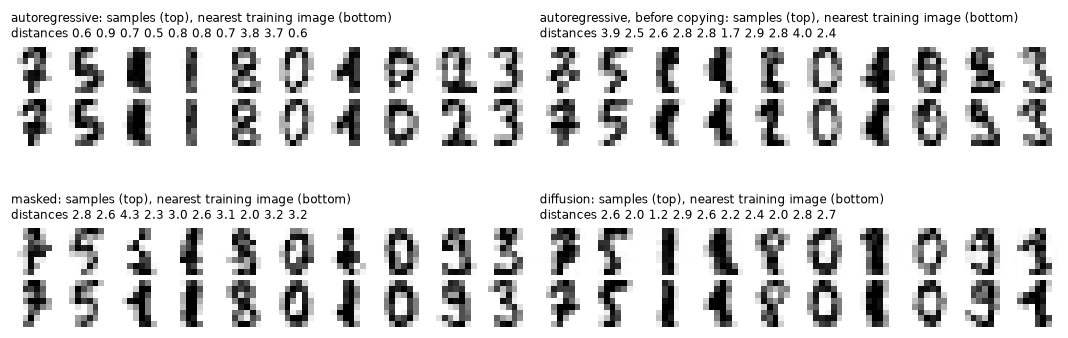

In [9]:
early = copy.deepcopy(IMG["autoregressive"]["model"]); early.load_state_dict(IMG["autoregressive"]["snaps"][best])
SAMPLES["autoregressive, early stop"] = sample_images("autoregressive", early)
name_early = f"autoregressive over tokens, stopped at step {best}"
ROWS_I[name_early] = dict(score(SAMPLES["autoregressive, early stop"], name_early, 16), params=IMG["autoregressive"]["params"],
                          train_seconds=IMG["autoregressive"]["seconds"] * best / STEPS_I)
log_ar = IMG["autoregressive"]["log"]
clean = int(max([s for s in log_ar.index if log_ar.copies[s] < 0.05] or [best]))        # the last measurement with fewer than 5% copies
ar_clean = copy.deepcopy(IMG["autoregressive"]["model"]); ar_clean.load_state_dict(IMG["autoregressive"]["snaps"][clean])
SAMPLES["autoregressive, before copying"] = sample_images("autoregressive", ar_clean)
name_clean = f"autoregressive over tokens, stopped at step {clean}"
ROWS_I[name_clean] = dict(score(SAMPLES["autoregressive, before copying"], name_clean, 16), params=IMG["autoregressive"]["params"],
                          train_seconds=IMG["autoregressive"]["seconds"] * clean / STEPS_I)
t_img = pd.DataFrame([held] + list(ROWS_I.values())).set_index("model")[cols]
display(t_img.round(2))

fig, axes = plt.subplots(2, 2, figsize=(9.6, 3.3))
for ax, key in zip(axes.ravel(), ("autoregressive", "autoregressive, before copying", "masked", "diffusion")):
    x = SAMPLES[key][:10]; d, j = torch.cdist(x, Xtr).min(1)
    images.show_grid(torch.cat([x, Xtr[j]]), nrow=10, ax=ax)
    ax.set_title(f"{key}: samples (top), nearest training image (bottom)\ndistances " + " ".join(f"{v:.1f}" for v in d.tolist()), fontsize=8)
plt.show()

**What happened.**

* **Stopped at the lowest held-out loss (step 200)** the autoregressive model has an FD of 15.4, precision 0.70 and
  coverage 0.59, and the judge recognises the requested digit in 0.62 of its samples. That is far behind the masked
  model (8.4) and the Gaussian model (6.9).
* **At the last measurement before copying sets in (step 400, 2% copies)** it has an FD of 9.6, precision 0.78 and
  coverage 0.80. Its held-out loss has by then risen from 2.96 to 4.18.
* **In the picture**, eight of the first ten samples of the fully trained model lie within 0.5 to 0.9 of a training
  image, which is the rounding error of the tokenizer: they are the same image. The samples of the other three
  panels resemble their neighbours and differ from them.

So there is no stopping point at which this model is both honest and the best of the three. From here on, "the
autoregressive image model" means the two early-stopped versions, and the fully trained one is shown in grey.

**How far this goes.** One data set of 1,438 images, one seed and one codebook size. (In a development run with 64
codes the model memorised as well.) Autoregressive image models are trained on millions of images
([Esser et al., 2020](https://arxiv.org/abs/2012.09841), [Tian et al., 2024](https://arxiv.org/abs/2404.02905)), and the result says nothing about them. It does say that, at this ratio of data to
parameters, the same backbone overfitted under one objective and not under the other two.

## 6. What a sample costs

The three samplers differ in how many network evaluations they need, and in whether that number is a choice.

* The autoregressive sampler has no choice: 16 tokens, 16 evaluations.
* The masked sampler reveals the tokens in a number of rounds that we pick. One round predicts all 16 tokens at
  once, independently of each other. Sixteen rounds reveal one token at a time, in a random order. It also has a
  second design choice: **which** tokens to keep in each round. Masked diffusion keeps a random subset
  ([Sahoo et al., 2024](https://arxiv.org/abs/2406.07524)). MaskGIT keeps the predictions the model is most confident about ([Chang et al., 2022](https://arxiv.org/abs/2202.04200)).
* The Gaussian sampler takes any number of steps (notebook 07).

nfe,1,2,4,8,16,50
sampler,,,,,,
Gaussian diffusion,NaN,102.7,18.9,9.2,7.3,6.9
"autoregressive, 1,500 steps (copies)",NaN,NaN,NaN,NaN,5.2,NaN
"autoregressive, last step before copying",NaN,NaN,NaN,NaN,9.6,NaN
"autoregressive, lowest held-out loss",NaN,NaN,NaN,NaN,15.4,NaN
"masked diffusion, confidence order",11.8,9.1,14.7,15.4,18.5,NaN
"masked diffusion, random order",11.8,10.4,9.4,8.4,10.4,NaN


,fd,precision,coverage,copies
sampler,,,,
"masked diffusion, random order",10.38,0.87,0.82,0.00
"masked diffusion, confidence order",18.46,0.96,0.76,0.00
Gaussian diffusion,7.30,0.93,0.90,0.00
"autoregressive, lowest held-out loss",15.43,0.70,0.59,0.00
"autoregressive, last step before copying",9.56,0.78,0.80,0.02
"autoregressive, 1,500 steps (copies)",5.23,0.94,0.95,0.87


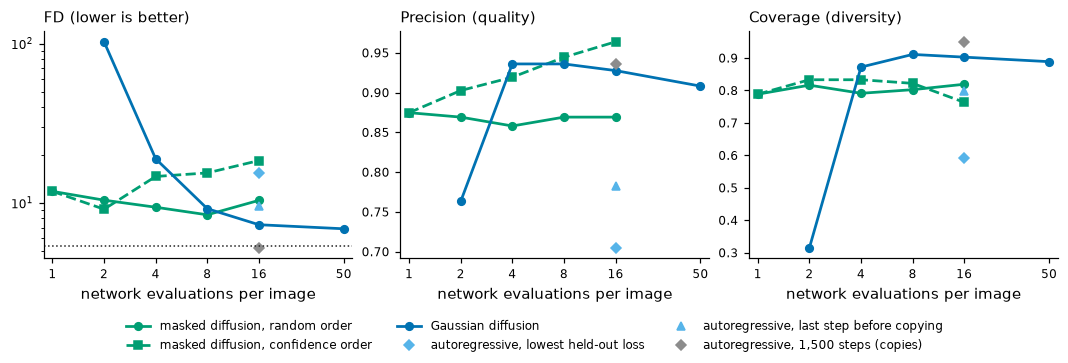

In [10]:
sweep = []
for steps in (1, 2, 4, 8, 16):
    for order in ("random", "confidence"):
        sweep.append(dict(score(sample_images("masked", IMG["masked"]["model"], steps, order), "", steps), sampler=f"masked diffusion, {order} order"))
for steps in (2, 4, 8, 16, 50):
    sweep.append(dict(score(sample_images("diffusion", IMG["diffusion"]["model"], steps), "", steps), sampler="Gaussian diffusion"))
sweep.append(dict(ROWS_I[name_early], sampler="autoregressive, lowest held-out loss"))
sweep.append(dict(ROWS_I[name_clean], sampler="autoregressive, last step before copying"))
sweep.append(dict(ROWS_I[names_i["autoregressive"]], sampler="autoregressive, 1,500 steps (copies)"))
sweep = pd.DataFrame(sweep)
display(sweep.pivot_table(index="sampler", columns="nfe", values="fd").round(1))
display(sweep[sweep.nfe == 16].set_index("sampler")[["fd", "precision", "coverage", "copies"]].round(2))

style = {"masked diffusion, random order": (viz.GREEN, "o-"), "masked diffusion, confidence order": (viz.GREEN, "s--"), "Gaussian diffusion": (viz.BLUE, "o-"),
         "autoregressive, lowest held-out loss": (viz.SKY, "D"), "autoregressive, last step before copying": (viz.SKY, "^"),
         "autoregressive, 1,500 steps (copies)": (viz.GREY, "D")}
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.2))
for ax, key, title in zip(axes, ("fd", "precision", "coverage"), ("FD (lower is better)", "Precision (quality)", "Coverage (diversity)")):
    for name, (c, fmt) in style.items():
        s = sweep[sweep.sampler == name].sort_values("nfe"); ax.plot(s.nfe, s[key], fmt, color=c, label=name, ms=5)
    ax.set_xscale("log", base=2); ax.set_xticks([1, 2, 4, 8, 16, 50]); ax.set_xticklabels([1, 2, 4, 8, 16, 50])
    ax.set_xlabel("network evaluations per image"); ax.set_title(title)
axes[0].set_yscale("log"); axes[0].axhline(REAL["fd"], color=viz.BLACK, lw=1, ls=":")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3, fontsize=8)
plt.show()

**What happened.**

* **Gaussian diffusion needs its steps.** FD 102.7 with 2 steps, 18.9 with 4, 9.2 with 8, 7.3 with 16 and 6.9 with
  50.
* **Masked diffusion is good from the first evaluation.** One round, in which all 16 tokens are drawn at once and
  independently, already gives 11.8. With random order the FD then goes 10.4, 9.4, 8.4 and 10.4 for 2, 4, 8 and 16
  rounds. Up to 8 evaluations the masked model is ahead of the Gaussian one; from 16 on it is behind.
* **Confidence order helps only at 2 rounds** (9.1 against 10.4) and then makes FD worse: 14.7, 15.4 and 18.5 for
  4, 8 and 16 rounds. The second table shows where the loss comes from. At 16 rounds confidence order has the
  highest precision of all samplers (0.96 against 0.87 for random order) and lower coverage (0.76 against 0.82).
  Keeping the most confident predictions first commits early to the most typical strokes, and the samples become
  typical digits. MaskGIT adds noise to the confidences, with a schedule, for this reason ([Chang et al., 2022](https://arxiv.org/abs/2202.04200)); we did
  not, and did not test it.
* **The autoregressive sampler** has one point, at 16 evaluations: 15.4 or 9.6 depending on where training stopped.

Sixteen random rounds being worse than eight (10.4 against 8.4) is a single-seed result; we would not build on it.

One reading of the masked model's good start: given the label, the patches of a digit are close to independent, so
one parallel guess is already reasonable. Section 9 asks the same question of text, where neighbouring tokens are
tightly coupled.

**Animation.** The three samplers at work on the same eight labels, 16 network evaluations each. The autoregressive
model writes patches in reading order. The masked model fills them in a random order. The Gaussian model starts from
noise everywhere and sharpens the whole image at once.

In [11]:
lab8 = torch.arange(8)
def decode_partial(f):                                     # tokens with -1 for "not yet written" -> images with grey patches
    p = U.patchify(tok.decode(f.clamp(min=0)), 2); p[f < 0] = 0.0
    return U.unpatchify(p, 2)

def generation_frames(n_eval=16):
    blank = torch.full((8, 16), -1)
    ar = [blank] + U.sample_ar(ar_clean, 8, 16, lab8, record=True)[1]
    mk = [blank] + U.sample_masked(IMG["masked"]["model"], 8, 16, n_eval, lab8, record=True)[1]
    x, fr = GAUSS.sample(IMG["diffusion"]["model"], lab8, steps=n_eval, record=True)
    return {"autoregressive": [decode_partial(f) for f in ar], "masked diffusion": [decode_partial(f) for f in mk],
            "Gaussian diffusion": [f[1] for f in fr] + [x]}
FRAMES = generation_frames()

def draw_generation(axes, i):
    for ax, (name, fr) in zip(axes, FRAMES.items()):
        ax.clear(); images.show_grid(fr[min(i, len(fr) - 1)], nrow=4, ax=ax); ax.set_title(f"{name}\nafter {i} of 16 evaluations", fontsize=9)

fig, axes = plt.subplots(1, 3, figsize=(8.4, 2.6))
gif = viz.save_gif(fig, lambda i: draw_generation(axes, min(i, 16)), list(range(17)) + [16] * 5, "nb10_three_samplers.gif", fps=3)

saved figures/nb10_three_samplers.gif  (22 frames drawn, 147 kB)


![Eight digits generated by the autoregressive, the masked and the Gaussian sampler, sixteen network evaluations each](figures/nb10_three_samplers.gif)

**Explorer.** Step through the same generation by hand.

Static preview at the default settings {'evaluations': 6}. Run the notebook to get the controls.


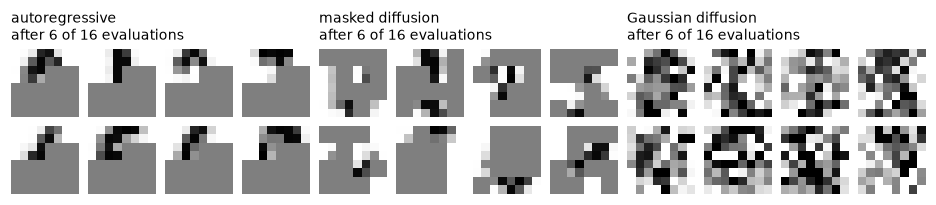

In [12]:
def generation_at(evaluations):
    fig, axes = plt.subplots(1, 3, figsize=(8.4, 2.6)); draw_generation(axes, evaluations); plt.show()
viz.explore(generation_at, evaluations=(0, 16, 1, 6))

## 7. Three objectives on language

The same experiment on the synthetic language of notebooks 01 to 05. Its documents are 64 tokens long: a start
token, filler words whose order depends on a hidden style, and statements `set K V` that bind a key to a value and
`ask K V` that recall it. A model is good when it gets three things right: the grammar of the statements, the
recall of bound values, and the word order of the style.

The three language models use the backbone of section 2 with rotary positions, the optimiser of the image models,
batch size 128 and 3,000 steps.

| | Input | Loss | What we can measure |
|---|---|---|---|
| Autoregressive | 64 tokens | cross-entropy of every token given the earlier ones | the exact loss per token, and its gap to the best possible predictor |
| Masked diffusion | 64 tokens, a random share masked | cross-entropy of the hidden tokens, weighted by 1 / share | an upper bound on the loss per token |
| Gaussian diffusion | 64 noisy word vectors | cross-entropy of every token | no likelihood: samples only |

Because only the autoregressive model has an exact likelihood, the comparison that covers all three is on
**samples**: 256 documents from each model, checked with the rules of the language (`document_checks`, notebook 04).
Every 250 steps we record the loss gap where there is one, and the checks on 64 samples.

In [13]:
FLOOR500 = float(-W.corpus("test")["logp_bayes"][:500, 1:].mean())           # the floor on the 500 documents used during training
checks = lambda docs: {k: float(v) for k, v in O.document_checks(docs).items()}
NFE_L = {"autoregressive": 63, "masked": 63, "embedding": 50}                 # network evaluations per document of the default sampler

def sample_docs(kind, model, n=256, steps=None, order="confidence", seed=0, record=False):
    if kind == "autoregressive":
        return U.sample_ar(model, n, W.DOC_LEN, first=W.BOS, forbid=FORBID, seed=seed, record=record)
    if kind == "masked":
        return U.sample_masked(model, n, W.DOC_LEN, steps or 63, first=W.BOS, forbid=FORBID, order=order, seed=seed, record=record)
    return EMB.sample(model, n, W.DOC_LEN, steps=steps or 50, first=W.BOS, forbid=FORBID, seed=seed, record=record)

def train_lm(kind, positions="rotary", steps=STEPS_L, seed=0):
    set_seed(seed)
    pos = U.Rotary(W.DOC_LEN) if positions == "rotary" else U.sincos_1d(W.DOC_LEN, 64)
    if kind == "autoregressive":
        net, obj = U.Discrete(W.VOCAB, pos, causal=True), U.Autoregressive(first_fixed=True)
    elif kind == "masked":
        net, obj = U.Discrete(W.VOCAB, pos, causal=False), U.MaskedDiffusion(first_fixed=True)
    else:
        net, obj = U.Continuous(EMB.dim, W.VOCAB, pos), EMB
    log = []
    def measure(step, raw, ema):
        with torch.no_grad():
            loss = float(obj.loss(ema, TE_L[:500])) if kind == "autoregressive" else obj.bound(ema, TE_L[:500], repeats=2) if kind == "masked" else float("nan")
        log.append(dict(step=step, gap=loss - FLOOR500, **checks(sample_docs(kind, ema, 64, steps=16))))
    out = D.train(net, obj, TR_L, NO_LABEL, steps=steps, seed=seed, callback=measure, every=250)
    out.update(kind=kind, positions=positions, obj=obj, log=pd.DataFrame(log).set_index("step"), params=U.n_params(net))
    print(f"{kind:15s} {positions:10s} positions: {out['params']:,} parameters, {steps} steps, {out['seconds']:.0f} s")
    return out

LM = {(kind, "rotary"): train_lm(kind) for kind in ("autoregressive", "masked", "embedding")}

autoregressive  rotary     positions: 242,961 parameters, 3000 steps, 262 s
masked          rotary     positions: 242,961 parameters, 3000 steps, 257 s
embedding       rotary     positions: 251,153 parameters, 3000 steps, 258 s


,samples: grammar,samples: asks bound,samples: recall,samples: word order,gap,likelihood,nfe,params,train_seconds
model,,,,,,,,,
real held-out documents,1.000,1.000,1.000,0.797,NaN,NaN,NaN,NaN,NaN
autoregressive,0.993,0.986,0.612,0.759,0.055,exact,63.0,242961.0,262.233
masked diffusion,0.990,0.717,0.143,0.371,0.568,upper bound,63.0,242961.0,256.525
Gaussian diffusion on word vectors,0.845,0.210,0.260,0.317,NaN,none,50.0,251153.0,257.999


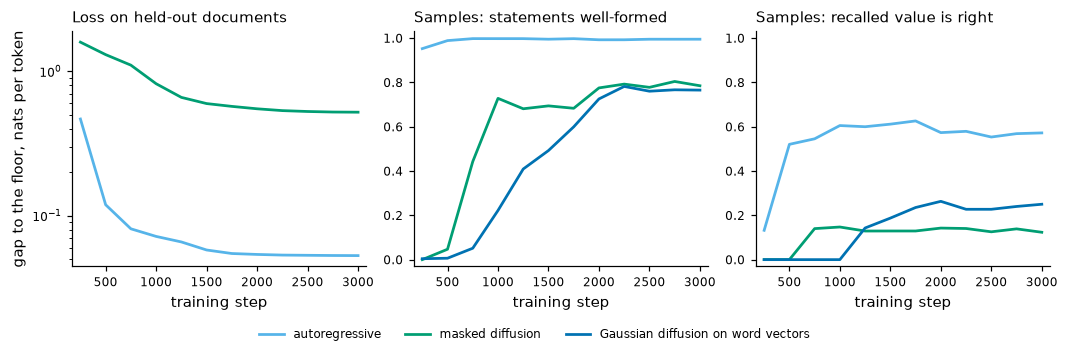

In [14]:
names_l = {"autoregressive": "autoregressive", "masked": "masked diffusion", "embedding": "Gaussian diffusion on word vectors"}

def report_lm(kind, positions="rotary"):
    r = LM[(kind, positions)]; m = r["model"]
    row = dict(model=names_l[kind], positions=positions, gap=float("nan"), likelihood="none", nfe=NFE_L[kind], params=r["params"], train_seconds=r["seconds"])
    if kind == "autoregressive":
        r["res"] = W.evaluate_lm(U.logprobs_ar(m)); row.update(gap=r["res"]["gap"], likelihood="exact")
    elif kind == "masked":
        row.update(gap=r["obj"].bound(m, TE_L) - FLOOR, likelihood="upper bound")
    r["docs"] = sample_docs(kind, m)
    row.update({"samples: " + k: v for k, v in checks(r["docs"]).items()})
    return row

t_lm = pd.DataFrame([dict(model="real held-out documents", **{"samples: " + k: v for k, v in checks(TE_L[:256]).items()})]
                    + [report_lm(kind) for kind in names_l]).set_index("model")
display(t_lm.drop(columns="positions").round(3))

lcol = {"autoregressive": viz.SKY, "masked": viz.GREEN, "embedding": viz.BLUE}
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.1))
for kind in ("autoregressive", "masked"):
    axes[0].plot(LM[(kind, "rotary")]["log"].index, LM[(kind, "rotary")]["log"].gap, color=lcol[kind], label=names_l[kind] + (" (bound)" if kind == "masked" else ""))
axes[0].set_yscale("log"); axes[0].set_ylabel("gap to the floor, nats per token"); axes[0].set_title("Loss on held-out documents")
for ax, key, title in ((axes[1], "grammar", "Samples: statements well-formed"), (axes[2], "recall", "Samples: recalled value is right")):
    for kind in names_l:
        ax.plot(LM[(kind, "rotary")]["log"].index, LM[(kind, "rotary")]["log"][key], color=lcol[kind], label=names_l[kind])
    ax.set_ylim(-0.03, 1.03); ax.set_title(title)
for ax in axes:
    ax.set_xlabel("training step")
fig.legend(*axes[1].get_legend_handles_labels(), loc="outside lower center", ncol=3, fontsize=8)
plt.show()

**What happened.**

* **The autoregressive model is far ahead.** Its loss is 0.055 nats per token above the floor. Its samples are
  well-formed (grammar 0.99, queries of bound keys 0.99) and follow the word order of a style almost as often as
  real documents do (0.76 against 0.80). Its weak point is recall in its own samples: the value after `ask K` is the
  right one 61% of the time.
* **Masked diffusion learned the local structure and little else.** Statements are well-formed (0.99), but the
  recalled value is right 14% of the time, where a blind guess among 8 values gives 12.5%, and the word order
  follows a style 37% of the time. Its bound is 0.568 above the floor: ten times the gap of the autoregressive
  model.
* **Gaussian diffusion on word vectors** is at a similar level: grammar 0.84, recall 0.26, word order 0.32.
* **The curves** show how early the difference appears. The autoregressive model writes well-formed statements after
  250 steps. The other two need 1,000 to 2,000 steps to get most statements right, and their recall stays near
  chance to the end.

Why would the same backbone learn so much faster with the autoregressive objective? A reading, not a test. Recall
needs one specific earlier token: the value bound to the key. The autoregressive model always sees it. The masked
model sees a random subset, so in many training examples the token that the answer depends on is itself hidden, and
only part of the training signal teaches recall. The noisy word vectors of the Gaussian model blur it in the same
way. Published masked diffusion language models narrow the gap to autoregressive ones, with more
training and larger models ([Sahoo et al., 2024](https://arxiv.org/abs/2406.07524), [Nie et al., 2025](https://arxiv.org/abs/2502.09992)). In a development run of 6,000 steps (not in this notebook)
the masked model reached a bound of 0.53 above the floor, and the autoregressive model a gap of 0.02.

**A masked model can be read left to right.** The bound of the masked model is not the number the series has used
for language models. To put it on the scorecard next to notebooks 01 to 05 we use it as an autoregressive model: to
predict token $t$, mask token $t$ and everything after it. That takes one network evaluation per position, and it
gives a true loss per token and the recall test of the earlier notebooks.

In [15]:
t0 = time.time()
LM[("masked", "rotary")]["res"] = W.evaluate_lm(U.logprobs_masked(LM[("masked", "rotary")]["model"]))
print(f"evaluated in {time.time() - t0:.0f} s")
ar, mk = LM[("autoregressive", "rotary")]["res"], LM[("masked", "rotary")]["res"]
display(pd.DataFrame({"autoregressive": {"gap to the floor": ar["gap"], "recall, mean over distances": ar["recall_mean"], "recall at distance 8": ar["recall"][8], "recall at distance 32": ar["recall"][32]},
                      "masked diffusion, read left to right": {"gap to the floor": mk["gap"], "recall, mean over distances": mk["recall_mean"], "recall at distance 8": mk["recall"][8], "recall at distance 32": mk["recall"][32]}}).round(3))

evaluated in 41 s


,autoregressive,"masked diffusion, read left to right"
gap to the floor,0.055,0.565
"recall, mean over distances",1.000,0.151
recall at distance 8,1.000,0.186
recall at distance 32,1.000,0.132


**What happened.** Read left to right, the masked model has a gap of 0.565, almost exactly its bound (0.568). Its
recall on the test of notebooks 01 to 05 is 0.15 on average, against 1.00 for the autoregressive model. The
evaluation needs 63 network evaluations per document and took about 40 seconds. This row goes on the series scorecard.

**Animation.** One document from each model. The autoregressive model writes left to right (four tokens per frame).
The masked model starts from a fully masked document and keeps the predictions it is most confident about. The
Gaussian model has a guess for every word from the first step, and revises all of them at every step.
Keys are blue, values orange, `set` and `ask` dark.

In [16]:
def text_frames(seed=1):
    get = lambda kind: LM[(kind, "rotary")]["model"]
    ar = sample_docs("autoregressive", get("autoregressive"), 1, seed=seed, record=True)[1]
    mk = sample_docs("masked", get("masked"), 1, steps=16, seed=seed, record=True)[1]
    em = sample_docs("embedding", get("embedding"), 1, steps=16, seed=seed, record=True)[1]
    blank = torch.full((W.DOC_LEN,), -1); blank[0] = W.BOS
    return {"autoregressive": [blank] + [ar[min(len(ar) - 1, 4 * i + 3)][0] for i in range(16)],
            "masked diffusion": [blank] + [f[0] for f in mk], "Gaussian diffusion on word vectors": [em[0][0]] + [f[0] for f in em]}
TEXT = text_frames()

def strip(ax, toks, title):
    toks = [int(t) for t in toks]
    words = ["" if t < 0 else W.WORDS[t] for t in toks]
    colors = [HIDDEN if t < 0 else c for t, c in zip(toks, viz.doc_colors([max(t, 0) for t in toks]))]
    ax.clear(); viz.token_strip(ax, words, colors=colors, wrap=16, fontsize=6.5); ax.set_title(title, fontsize=9)

def draw_text(axes, i):
    for ax, (name, fr) in zip(axes, TEXT.items()):
        strip(ax, fr[min(i, len(fr) - 1)], f"{name}, step {min(i, len(fr) - 1)} of {len(fr) - 1}")

fig, axes = plt.subplots(3, 1, figsize=(8.8, 6.0))
gif = viz.save_gif(fig, lambda i: draw_text(axes, i), list(range(17)) + [16] * 5, "nb10_three_writers.gif", fps=3)
print("checks on the three finished documents:")
for name, fr in TEXT.items():
    print(f"  {name:36s}", {k: round(v, 2) for k, v in checks(fr[-1][None]).items()})

saved figures/nb10_three_writers.gif  (22 frames drawn, 116 kB)


checks on the three finished documents:
  autoregressive                       {'grammar': 1.0, 'asks bound': 1.0, 'recall': 0.25, 'word order': 0.93}
  masked diffusion                     {'grammar': 0.88, 'asks bound': 0.93, 'recall': 0.08, 'word order': 0.33}
  Gaussian diffusion on word vectors   {'grammar': 1.0, 'asks bound': 0.0, 'recall': 0.0, 'word order': 0.34}


![One document written by each of the three language models: left to right, by unmasking, and by denoising word vectors](figures/nb10_three_writers.gif)

**What to look for.** At step 0 the input of the Gaussian model is pure noise, and its guess for every position is
the most frequent token there: `set` near the start of a document, `ask` later. The autoregressive model never
revises a token; the masked model never revises a token once it is revealed; the Gaussian model revises everything
until the last step. The checks printed above are for these three single documents and are an illustration only.

## 8. A design choice that the objective exposes: positions

The first version of this notebook used the fixed sinusoidal position vectors of the 2017 transformer
([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)) for the language models, as the image models do. The autoregressive model trained normally. The
two models that see the whole sequence did not: after 1,500 steps fewer than 1% of the statements in their samples
were well-formed (development runs, not shown).
Switching the language models to rotary positions ([Su et al., 2021](https://arxiv.org/abs/2104.09864)) changed that. Rotary positions were chosen after
seeing the sinusoidal models fail, so this section repeats the comparison in the open: the same three models with
sinusoidal positions, everything else equal.

autoregressive  sinusoidal positions: 242,961 parameters, 3000 steps, 221 s
masked          sinusoidal positions: 242,961 parameters, 3000 steps, 226 s
embedding       sinusoidal positions: 251,153 parameters, 3000 steps, 231 s


gap   likelihood  samples: grammar  samples: asks bound  samples: recall  samples: word order
model                              positions                                                                                                  
autoregressive                     sinusoidal  0.055        exact             0.995                0.998            0.628                0.765
                                   rotary      0.055        exact             0.993                0.986            0.612                0.759
masked diffusion                   sinusoidal  1.218  upper bound             0.301                0.249            0.152                0.296
                                   rotary      0.568  upper bound             0.990                0.717            0.143                0.371
Gaussian diffusion on word vectors sinusoidal    NaN         none             0.004                0.000            0.000                0.220
                                   rotary        NaN         none             0.845                0.210            0.260                0.317

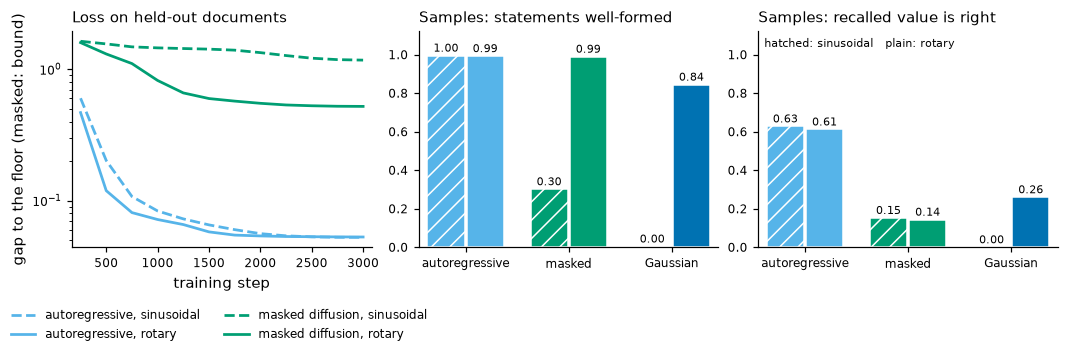

In [17]:
for kind in names_l:
    LM[(kind, "sinusoidal")] = train_lm(kind, "sinusoidal")
t_pos = pd.DataFrame([report_lm(kind, p) for kind in names_l for p in ("sinusoidal", "rotary")]).set_index(["model", "positions"])
display(t_pos[["gap", "likelihood", "samples: grammar", "samples: asks bound", "samples: recall", "samples: word order"]].round(3))

fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.1))
for kind in ("autoregressive", "masked"):
    for p, ls in (("sinusoidal", "--"), ("rotary", "-")):
        axes[0].plot(LM[(kind, p)]["log"].index, LM[(kind, p)]["log"].gap, color=lcol[kind], ls=ls, label=f"{names_l[kind]}, {p}")
axes[0].set_yscale("log"); axes[0].set_xlabel("training step"); axes[0].set_ylabel("gap to the floor (masked: bound)"); axes[0].set_title("Loss on held-out documents")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower left", ncol=2, fontsize=8)
x = np.arange(3)
for ax, key, title in ((axes[1], "samples: grammar", "Samples: statements well-formed"), (axes[2], "samples: recall", "Samples: recalled value is right")):
    for j, (p, hatch) in enumerate((("sinusoidal", "//"), ("rotary", None))):
        vals = [t_pos.loc[(names_l[k], p), key] for k in names_l]
        bars = ax.bar(x + (j - 0.5) * 0.38, vals, 0.36, color=[lcol[k] for k in names_l], hatch=hatch, edgecolor="white", label=p)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(["autoregressive", "masked", "Gaussian"], fontsize=8); ax.set_ylim(0, 1.12); ax.set_title(title)
axes[2].text(0.02, 0.97, "hatched: sinusoidal   plain: rotary", transform=axes[2].transAxes, fontsize=7, va="top")
plt.show()

**What happened.**

* **Autoregressive: no difference.** A gap of 0.055 with either scheme, and the same sample quality.
* **Masked diffusion: a large difference.** With sinusoidal positions the bound is 1.218 above the floor and 30% of
  the statements in the samples are well-formed. With rotary positions: 0.568 and 99%.
* **Gaussian diffusion on word vectors: larger still.** 0.4% of statements well-formed with sinusoidal positions,
  84% with rotary positions.

A reading that fits all three rows, and that the notebook does not test further. The grammar of this language is
about neighbours: `set` is followed by a key and then by a value. A causal model gets order for free. Each position
attends to a different set of earlier tokens, and causal transformers learn positions even with no position signal
at all ([Haviv et al., 2022](https://arxiv.org/abs/2203.16634)). A model that sees both sides has only the position vectors, and to find "the token just
before me" from added sinusoids it has to learn to compare two of them. Rotary positions put the offset between two
tokens directly into their attention score.

This connects three earlier results. In notebook 03 a causal model did equally well with sinusoidal and relative
positions inside the training length. In notebook 04 an encoder failed with no positions, and trained much faster
with a relative bias than with RoPE. In notebook 09 the image models, which also see both sides, did best with
sinusoidal positions: they have 16 tokens on a 4×4 grid, and no grammar of neighbours. A relative bias was not
tried on this backbone.

**Caveats.** One seed and 3,000 steps. The sinusoidal masked model is still improving at the end of its curve: it
is slower, not incapable. And the order of events matters for how to read this section: rotary positions were
chosen after the sinusoidal models had failed, not before.

## 9. What a document costs

The same question as section 6, for text. The autoregressive model needs 63 network evaluations for 63 tokens. The
masked model can reveal several tokens per round, and the Gaussian model can take any number of steps. How few
evaluations are enough for a well-formed document?

"grammar, by evaluations",4,8,16,32,50,63,200
sampler,,,,,,,
Gaussian diffusion on word vectors,0.51,0.73,0.78,NaN,0.84,NaN,0.86
autoregressive,NaN,NaN,NaN,NaN,NaN,0.99,NaN
"masked diffusion, confidence order",0.36,0.63,0.80,0.91,NaN,0.99,NaN
"masked diffusion, random order",0.34,0.54,0.71,0.80,NaN,0.87,NaN


"recall, by evaluations",4,8,16,32,50,63,200
sampler,,,,,,,
Gaussian diffusion on word vectors,0.38,0.26,0.26,NaN,0.26,NaN,0.26
autoregressive,NaN,NaN,NaN,NaN,NaN,0.61,NaN
"masked diffusion, confidence order",0.09,0.16,0.13,0.15,NaN,0.14,NaN
"masked diffusion, random order",0.13,0.13,0.10,0.18,NaN,0.13,NaN


"word order, by evaluations",4,8,16,32,50,63,200
sampler,,,,,,,
Gaussian diffusion on word vectors,0.28,0.30,0.31,NaN,0.32,NaN,0.32
autoregressive,NaN,NaN,NaN,NaN,NaN,0.76,NaN
"masked diffusion, confidence order",0.34,0.35,0.36,0.37,NaN,0.37,NaN
"masked diffusion, random order",0.33,0.35,0.36,0.37,NaN,0.37,NaN


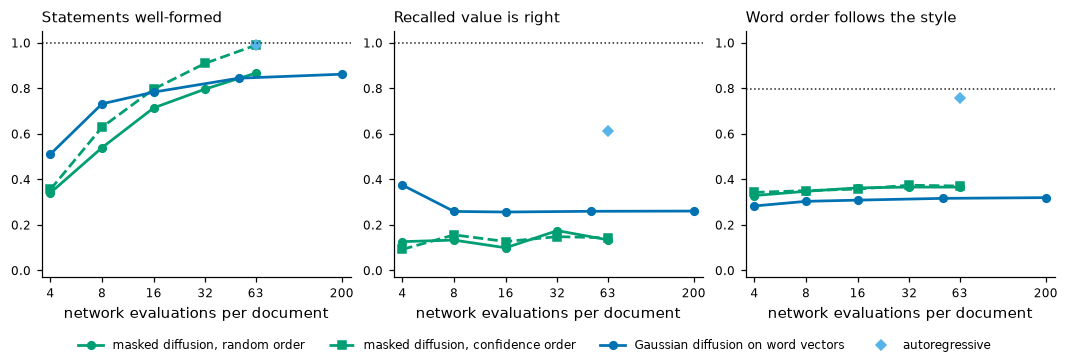

In [18]:
cost = [dict(sampler="autoregressive", nfe=63, **checks(LM[("autoregressive", "rotary")]["docs"]))]
for steps in (4, 8, 16, 32, 63):
    for order in ("random", "confidence"):
        cost.append(dict(sampler=f"masked diffusion, {order} order", nfe=steps, **checks(sample_docs("masked", LM[("masked", "rotary")]["model"], steps=steps, order=order))))
for steps in (4, 8, 16, 50, 200):
    cost.append(dict(sampler="Gaussian diffusion on word vectors", nfe=steps, **checks(sample_docs("embedding", LM[("embedding", "rotary")]["model"], steps=steps))))
cost = pd.DataFrame(cost)
for key in ("grammar", "recall", "word order"):
    display(cost.pivot_table(index="sampler", columns="nfe", values=key).round(2).rename_axis(columns=key + ", by evaluations"))

lstyle = {"masked diffusion, random order": (viz.GREEN, "o-"), "masked diffusion, confidence order": (viz.GREEN, "s--"),
          "Gaussian diffusion on word vectors": (viz.BLUE, "o-"), "autoregressive": (viz.SKY, "D")}
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.2))
for ax, key, title in zip(axes, ("grammar", "recall", "word order"), ("Statements well-formed", "Recalled value is right", "Word order follows the style")):
    for name, (c, fmt) in lstyle.items():
        s = cost[cost.sampler == name].sort_values("nfe"); ax.plot(s.nfe, s[key], fmt, color=c, label=name, ms=5)
    real = checks(TE_L[:256])[key]; ax.axhline(real, color=viz.BLACK, lw=1, ls=":")
    ax.set_xscale("log", base=2); ax.set_xticks([4, 8, 16, 32, 63, 200]); ax.set_xticklabels([4, 8, 16, 32, 63, 200])
    ax.set_ylim(-0.03, 1.05); ax.set_xlabel("network evaluations per document"); ax.set_title(title)
fig.legend(*axes[1].get_legend_handles_labels(), loc="outside lower center", ncol=4, fontsize=8)
plt.show()

**What happened.**

* **For text, fewer evaluations cost grammar directly.** Masked diffusion with confidence order writes well-formed
  statements at a rate of 0.36, 0.63, 0.80, 0.91 and 0.99 with 4, 8, 16, 32 and 63 rounds. A statement is three
  tokens that have to agree, and tokens revealed in the same round are drawn independently of each other.
* **At 63 rounds the masked model matches the autoregressive model on grammar** (0.99), at the same cost: one token
  per evaluation. There is no saving at equal quality.
* **Confidence order helps here** (0.99 against 0.87 for random order at 63 rounds), where it hurt the FD of images
  in section 6. The two results do not conflict: on images the cost was diversity, and the grammar check does not
  measure diversity.
* **Gaussian diffusion saturates**: 0.51, 0.73, 0.78, 0.84 and 0.86 with 4, 8, 16, 50 and 200 steps. Beyond 50
  steps its remaining errors are not sampling errors.
* **Recall and word order do not improve with more evaluations** for either model (second and third table). They
  are what the models have not learned, and no sampler can add it.

Generating text in a few parallel rounds is the main attraction of diffusion language models. This experiment shows
the condition attached: the saving is real only when the model is good enough that a few rounds suffice. This one
writes 80% of its statements correctly with 16 rounds.

## 10. What the hidden states are good for

Pretraining is also judged by its features (notebooks 02, 04 and 08). We freeze the six models, average the hidden
states of the last block over the sequence, and fit a linear classifier on a few labelled examples:

* **images**: which digit, from 1, 5 or 20 labelled images per digit (the test of notebook 08). The models are given
  the "no label" class, so the label cannot leak in;
* **language**: which style and which topic generated a document, from 15 or 100 labelled documents (the test of
  notebook 04).

A Gaussian diffusion model has one more setting: the noise level at which the features are read. The first plot
scans it. The tables use timestep 100 for images and 200 for text, fixed before looking at the scan.

Gaussian diffusion features, digit accuracy with 5 labels per digit, by timestep: {0: 0.6, 25: 0.59, 50: 0.62, 100: 0.63, 200: 0.63, 400: 0.45, 600: 0.25, 800: 0.14}


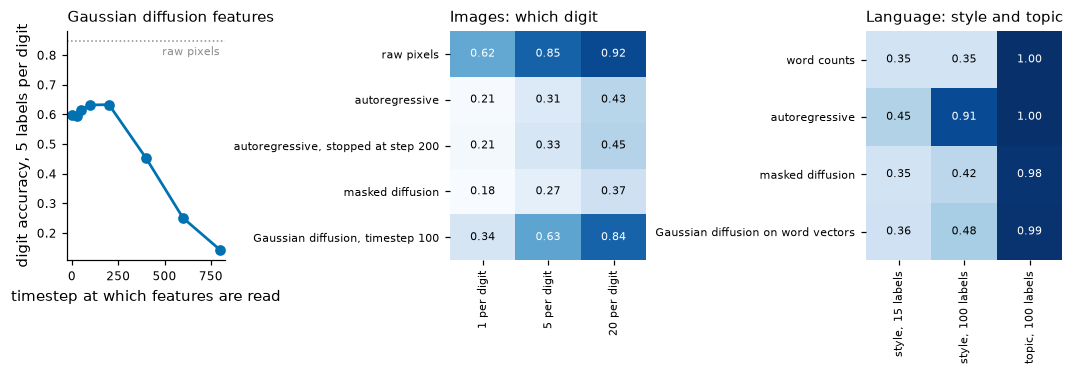

,1 per digit,5 per digit,20 per digit
raw pixels,0.62,0.85,0.92
autoregressive,0.21,0.31,0.43
"autoregressive, stopped at step 200",0.21,0.33,0.45
masked diffusion,0.18,0.27,0.37
"Gaussian diffusion, timestep 100",0.34,0.63,0.84


,"style, 15 labels","style, 100 labels","topic, 100 labels"
word counts,0.35,0.35,1.00
autoregressive,0.45,0.91,1.00
masked diffusion,0.35,0.42,0.98
Gaussian diffusion on word vectors,0.36,0.48,0.99


In [19]:
NOLAB = lambda n: torch.full((n,), D.NULL)
def token_features(model):
    return lambda X: U.mean_hidden(model, tok.encode(X), NOLAB(len(X)))
def diffusion_features(t):
    def fn(X):
        tt = torch.full((len(X),), t); eps = torch.randn(X.shape, generator=torch.Generator().manual_seed(0))
        return U.mean_hidden(IMG["diffusion"]["model"], GAUSS.q_sample(X, tt, eps), tt, NOLAB(len(X)))
    return fn
def lm_features(kind, t=200):
    model = LM[(kind, "rotary")]["model"]
    def fn(tokens):
        x = torch.as_tensor(tokens)
        if kind != "embedding":
            return U.mean_hidden(model, x).numpy()
        tt = torch.full((len(x),), t)
        return U.mean_hidden(model, EMB.noised(x, tt, torch.Generator().manual_seed(0)), tt).numpy()
    return fn
bag_of_words = lambda tokens: np.stack([np.bincount(r, minlength=W.VOCAB) for r in np.asarray(tokens)]).astype(float)

image_feats = {"raw pixels": lambda X: X, "autoregressive": token_features(IMG["autoregressive"]["model"]),
               f"autoregressive, stopped at step {best}": token_features(early), "masked diffusion": token_features(IMG["masked"]["model"]),
               "Gaussian diffusion, timestep 100": diffusion_features(100)}
p_img = pd.DataFrame({name: {f"{k} per digit": V.probe(fn, Xtr, ytr, Xte, yte, per_class=k) for k in (1, 5, 20)} for name, fn in image_feats.items()}).T
lm_feats = {"word counts": bag_of_words, **{names_l[k]: lm_features(k) for k in names_l}}
p_lm = pd.DataFrame({name: {f"{label}, {n} labels": float(np.mean([W.probe(fn, n, label, seed=s) for s in range(3)]))
                            for label, n in (("style", 15), ("style", 100), ("topic", 100))} for name, fn in lm_feats.items()}).T
scan_t = (0, 25, 50, 100, 200, 400, 600, 800)
scan = [V.probe(diffusion_features(t), Xtr, ytr, Xte, yte, per_class=5) for t in scan_t]
print("Gaussian diffusion features, digit accuracy with 5 labels per digit, by timestep:", {t: round(a, 2) for t, a in zip(scan_t, scan)})

fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.3), gridspec_kw=dict(width_ratios=[1, 1.25, 1.25]))
axes[0].plot(scan_t, scan, "o-", color=viz.BLUE); axes[0].axhline(p_img.loc["raw pixels", "5 per digit"], color=viz.GREY, ls=":", lw=1)
axes[0].annotate("raw pixels", (0.97, p_img.loc["raw pixels", "5 per digit"]), xycoords=("axes fraction", "data"), xytext=(0, -9), textcoords="offset points", ha="right", fontsize=7, color=viz.GREY)
axes[0].set_xlabel("timestep at which features are read"); axes[0].set_ylabel("digit accuracy, 5 labels per digit"); axes[0].set_title("Gaussian diffusion features")
for ax, t, title in ((axes[1], p_img, "Images: which digit"), (axes[2], p_lm, "Language: style and topic")):
    viz.heat(ax, t.values, xlabels=list(t.columns), ylabels=list(t.index), annotate=True, cmap="Blues", vmin=0.2, vmax=1.0)
    ax.set_title(title); ax.tick_params(axis="x", labelsize=7); ax.tick_params(axis="y", labelsize=7)
plt.show()
display(p_img.round(2)); display(p_lm.round(2))

**What happened.**

* **Images: no generator beats raw pixels.** Raw pixels give 0.62, 0.85 and 0.92 with 1, 5 and 20 labels per digit.
  The Gaussian diffusion model is closest (0.34, 0.63, 0.84). The token models are far behind (autoregressive 0.21,
  0.31, 0.43; masked 0.18, 0.27, 0.37). Stopping the autoregressive model early changes nothing.
* **The noise level matters for diffusion features.** The scan peaks at timesteps 100 to 200 (0.63), is slightly
  lower on clean images (0.60) and falls to 0.14 at timestep 800. Features are best where the model has real work
  to do and can still see the digit.
* **Language: the autoregressive model has the useful features.** Style is in the word order, so word counts are at
  chance (0.35 with either number of labels; three styles). The autoregressive model reaches 0.45 with 15 labels
  and 0.91 with 100. The masked model reaches 0.35 and 0.42, the Gaussian model 0.36 and 0.48. Topic is in the word
  counts and everything finds it.

Two readings, neither tested here.

* The image models were given the label in 90% of their training steps. Nothing forces a model to represent the
  digit when the digit is an input. The encoders of notebook 08 were trained without labels and reached 0.72 to 0.73
  with one label per digit.
* The language result reverses notebook 04, where a masked encoder gave the best frozen features. That encoder had
  learned the language. This masked diffusion model has not learned word order (section 7), so there is no style
  in its hidden states to read out. Features follow what a model has learned; the objective matters through that.

## 11. The six cells, and the series scorecard

The table collects one row per model. The cell then appends this notebook to `results/scorecard.csv` and draws the
best model of every notebook on the two scales the series has used: the gap to the best possible predictor for
language (notebooks 01 to 05, and here) and the FD for images (notebooks 06 to 09, and here).

quality   evaluations            likelihood
images   autoregressive      FD 15.4 (step 200), 9.6 (step 400); 5.2 at 1,500 steps with 87% copies            16                 exact
         masked diffusion                                                                    FD 8.4       1 to 16                 bound
         Gaussian diffusion                                                                  FD 6.9  any; 50 here  bound (not computed)
language autoregressive                               gap 0.055; samples: grammar 0.99, recall 0.61            63                 exact
         masked diffusion          gap 0.565 read left to right; samples: grammar 0.99, recall 0.14       4 to 63                 bound
         Gaussian diffusion                                      samples: grammar 0.84, recall 0.26  any; 50 here                  none

,model,gap,recall_mean,params
notebook,,,,
01_ngrams_embeddings,"window neural LM, 16 tokens",0.269,0.634,154737.0
02_recurrent,LSTM + dot-product attention,0.049,1.000,57105.0
03_transformer,"transformer, modern block, 13,500 steps",0.046,1.000,108817.0
04_objectives,"causal transformer (relative bias), 3,000 steps",0.039,1.000,109081.0
05_scaling,"causal transformer, 109k parameters, 3,000 steps",0.039,1.000,109081.0
10_capstone,"autoregressive, rotary positions",0.055,1.000,242961.0


,model,fd,precision,coverage,nfe
notebook,,,,,
06_image_generators,"WGAN-GP, median of 3 seeds",13.84,0.72,0.47,1.0
07_diffusion,final recipe,6.99,0.95,0.94,50.0
08_parts,"latent diffusion, no regulariser",6.50,0.96,0.98,50.0
09_dit,"base DiT, 3,000 steps",5.50,0.96,0.92,50.0
10_capstone,"Gaussian diffusion over patches, 50 steps",6.89,0.91,0.89,50.0


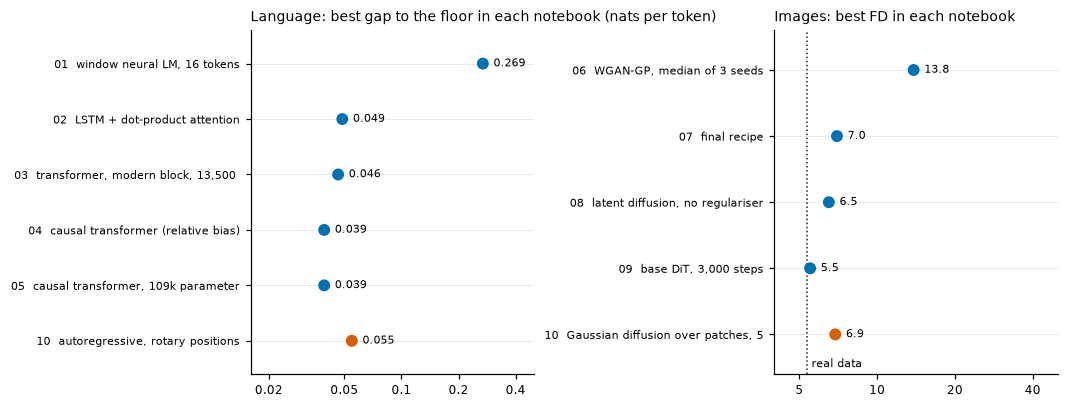

In [20]:
six = pd.DataFrame({
    ("images", "autoregressive"): {"quality": f"FD {ROWS_I[name_early]['fd']:.1f} (step {best}), {ROWS_I[name_clean]['fd']:.1f} (step {clean}); {ROWS_I[names_i['autoregressive']]['fd']:.1f} at 1,500 steps with {ROWS_I[names_i['autoregressive']]['copies']:.0%} copies",
                                    "evaluations": 16, "likelihood": "exact"},
    ("images", "masked diffusion"): {"quality": f"FD {ROWS_I[names_i['masked']]['fd']:.1f}", "evaluations": "1 to 16", "likelihood": "bound"},
    ("images", "Gaussian diffusion"): {"quality": f"FD {ROWS_I[names_i['diffusion']]['fd']:.1f}", "evaluations": "any; 50 here", "likelihood": "bound (not computed)"},
    ("language", "autoregressive"): {"quality": f"gap {ar['gap']:.3f}; samples: grammar {t_lm.loc['autoregressive', 'samples: grammar']:.2f}, recall {t_lm.loc['autoregressive', 'samples: recall']:.2f}",
                                      "evaluations": 63, "likelihood": "exact"},
    ("language", "masked diffusion"): {"quality": f"gap {mk['gap']:.3f} read left to right; samples: grammar {t_lm.loc['masked diffusion', 'samples: grammar']:.2f}, recall {t_lm.loc['masked diffusion', 'samples: recall']:.2f}",
                                        "evaluations": "4 to 63", "likelihood": "bound"},
    ("language", "Gaussian diffusion"): {"quality": f"samples: grammar {t_lm.loc[names_l['embedding'], 'samples: grammar']:.2f}, recall {t_lm.loc[names_l['embedding'], 'samples: recall']:.2f}",
                                          "evaluations": "any; 50 here", "likelihood": "none"}}).T
with pd.option_context("display.max_colwidth", 120):
    display(six)

rows = [dict(r, family="image") for r in ROWS_I.values()]
rows += [W.scorecard_row("autoregressive, rotary positions", ar, params=LM[("autoregressive", "rotary")]["params"], train_seconds=LM[("autoregressive", "rotary")]["seconds"]),
         W.scorecard_row("autoregressive, sinusoidal positions", LM[("autoregressive", "sinusoidal")]["res"], params=LM[("autoregressive", "sinusoidal")]["params"],
                         train_seconds=LM[("autoregressive", "sinusoidal")]["seconds"]),
         W.scorecard_row("masked diffusion read left to right, rotary positions", mk, params=LM[("masked", "rotary")]["params"], train_seconds=LM[("masked", "rotary")]["seconds"])]
metrics.append_rows(rows, "10_capstone");
sc = metrics.load_scorecard()
lang = sc[sc.gap.notna()]; best_l = lang.loc[lang.groupby("notebook").gap.idxmin()].set_index("notebook")
img = sc[sc.fd.notna() & (sc.model != "real data") & ~(sc.get("copies", pd.Series(0.0, index=sc.index)).fillna(0) > 0.2)]      # copying models are not candidates
best_i = img.loc[img.groupby("notebook").fd.idxmin()].set_index("notebook")
display(best_l[["model", "gap", "recall_mean", "params"]].round(3)); display(best_i[["model", "fd", "precision", "coverage", "nfe"]].round(2))

def log_axis(ax, ticks):                                   # a log axis with plain numbers at chosen ticks
    ax.set_xscale("log"); ax.set_xticks(ticks); ax.set_xticklabels([str(v) for v in ticks]); ax.minorticks_off()
    ax.set_xlim(ticks[0] * 0.8, ticks[-1] * 1.25)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
for ax, t, key, title in ((axes[0], best_l, "gap", "Language: best gap to the floor in each notebook (nats per token)"), (axes[1], best_i, "fd", "Images: best FD in each notebook")):
    y = np.arange(len(t))[::-1]
    ax.scatter(t[key], y, s=46, color=[viz.VERMILION if nb.startswith("10") else viz.BLUE for nb in t.index], zorder=3)
    for yy, (nb, r) in zip(y, t.iterrows()):
        ax.annotate(f"{r[key]:.3f}" if key == "gap" else f"{r[key]:.1f}", (r[key], yy), xytext=(7, 0), textcoords="offset points", va="center", fontsize=7)
    ax.set_yticks(y); ax.set_yticklabels([f"{nb[:2]}  {str(r.model)[:34]}" for nb, r in t.iterrows()], fontsize=7); ax.set_ylim(-0.6, len(t) - 0.4)
    log_axis(ax, [0.02, 0.05, 0.1, 0.2, 0.4] if key == "gap" else [5, 10, 20, 40]); ax.grid(axis="y", lw=0.4, color="#DDDDDD"); ax.set_title(title, fontsize=9)
axes[1].axvline(REAL["fd"], color=viz.BLACK, lw=1, ls=":")
axes[1].annotate("real data", (REAL["fd"], 0.02), xycoords=("data", "axes fraction"), xytext=(3, 0), textcoords="offset points", fontsize=7)
plt.show()

**What the series scorecard shows.**

* **Language.** The best gap fell from 0.269 (a window model, notebook 01) to 0.049 (LSTM with attention), 0.046
  (transformer) and 0.039 (notebooks 04 and 05). The capstone's autoregressive model is at 0.055 with 243,000
  parameters. It is not an improvement and was not meant as one: the backbone is the general one of this notebook,
  with a conditioning route that a language model does not need, and nothing about it was tuned for language.
* **Images.** The best FD fell from 13.8 (WGAN-GP) to 7.0 (diffusion design space), 6.5 (latent diffusion) and 5.5
  (diffusion transformer, 3,000 steps); real data scores 5.4. The capstone's Gaussian model is at 6.9 after 1,500
  steps.
* **One rule was applied to the image column**: a model with more than 20% copies is not a candidate. Without it the
  memorising autoregressive model would lead the series at 5.2.

**Explorer.** Pick a notebook to see every model it put on the scorecard.

Static preview at the default settings {'notebook': '10_capstone'}. Run the notebook to get the controls.


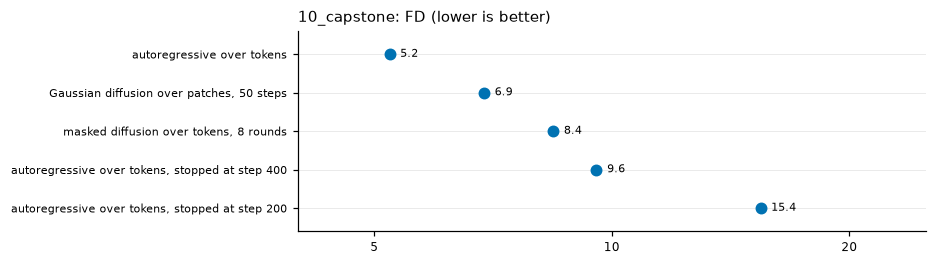

In [21]:
def show_notebook(notebook):
    t = sc[sc.notebook == notebook]; key = "gap" if t.gap.notna().sum() >= t.fd.notna().sum() else "fd"
    t = t[t[key].notna()].sort_values(key, ascending=False)
    fig, ax = plt.subplots(figsize=(8.4, 0.9 + 0.28 * len(t)))
    ax.scatter(t[key], range(len(t)), s=46, color=viz.BLUE, zorder=3)
    for i, v in enumerate(t[key]):
        ax.annotate(f"{v:.3f}" if key == "gap" else f"{v:.1f}", (v, i), xytext=(7, 0), textcoords="offset points", va="center", fontsize=7)
    ax.set_yticks(range(len(t))); ax.set_yticklabels([str(m)[:60] for m in t.model], fontsize=7); ax.set_ylim(-0.6, len(t) - 0.4)
    ticks = [v for v in ([0.02, 0.05, 0.1, 0.2, 0.5, 1, 2] if key == "gap" else [5, 10, 20, 50, 100, 200]) if t[key].min() * 0.5 < v < t[key].max() * 2]
    log_axis(ax, ticks if len(ticks) > 1 else [round(t[key].min() * 0.5, 3), round(t[key].max() * 2, 3)]); ax.grid(axis="y", lw=0.4, color="#DDDDDD")
    ax.set_title(f"{notebook}: " + ("gap to the floor, nats per token" if key == "gap" else "FD") + " (lower is better)")
    plt.show()
viz.explore(show_notebook, notebook=sorted(sc.notebook.unique(), reverse=True))

## 12. Where the field put its bets

The timeline places the papers of this series by publication date (read from the verified metadata in
`research_papers/`), language above and images below, coloured by objective. Grey marks papers about the
architecture or about another objective (contrastive, adversarial, variational).

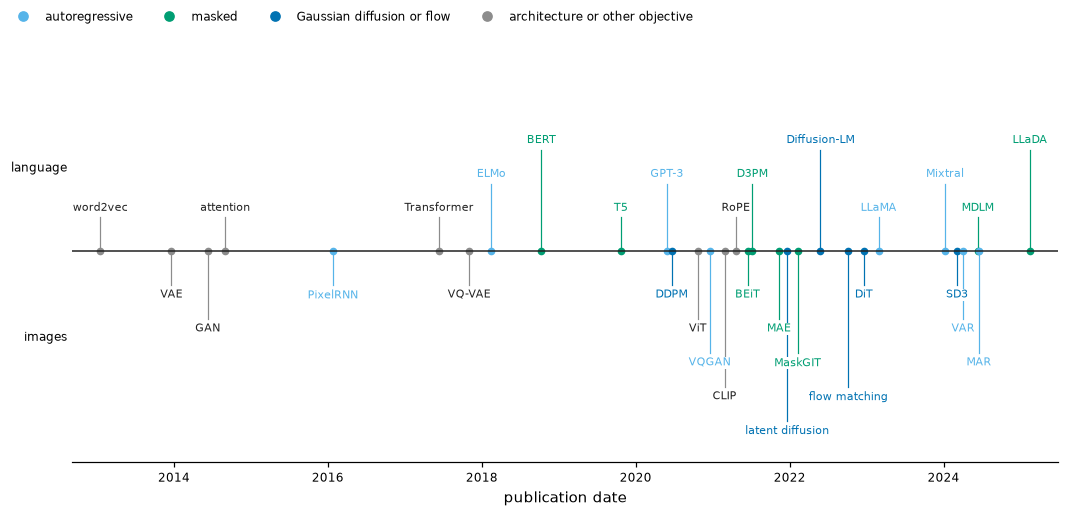

In [22]:
cat = json.load(open("research_papers/catalog.json"))["papers"]; meta = json.load(open("research_papers/papers_meta.json"))
when = lambda key: pd.Timestamp(meta[cat[key]["id"]]["published"])
AR_, MK_, GD_, OT_ = "autoregressive", "masked", "Gaussian diffusion or flow", "architecture or other objective"
OBJ_COL = {AR_: viz.SKY, MK_: viz.GREEN, GD_: viz.BLUE, OT_: viz.GREY}
MILESTONES = {
    "language": [("word2vec", "mikolov2013a", OT_), ("attention", "bahdanau2014", OT_), ("Transformer", "vaswani2017", OT_), ("ELMo", "peters2018", AR_),
                 ("BERT", "devlin2018", MK_), ("T5", "raffel2019", MK_), ("GPT-3", "brown2020", AR_), ("RoPE", "su2021", OT_), ("D3PM", "austin2021", MK_),
                 ("Diffusion-LM", "li2022", GD_), ("LLaMA", "touvron2023", AR_), ("Mixtral", "jiang2024", AR_), ("MDLM", "sahoo2024", MK_), ("LLaDA", "nie2025", MK_)],
    "images": [("VAE", "kingma2013", OT_), ("GAN", "goodfellow2014", OT_), ("PixelRNN", "oord2016", AR_), ("VQ-VAE", "oord2017", OT_), ("DDPM", "ho2020", GD_),
               ("ViT", "dosovitskiy2020", OT_), ("VQGAN", "esser2020", AR_), ("CLIP", "radford2021", OT_), ("BEiT", "bao2021", MK_), ("MAE", "he2021", MK_),
               ("latent diffusion", "rombach2021", GD_), ("MaskGIT", "chang2022", MK_), ("flow matching", "lipman2022", GD_), ("DiT", "peebles2022", GD_),
               ("SD3", "esser2024", GD_), ("VAR", "tian2024", AR_), ("MAR", "li2024", AR_)]}
fig, ax = plt.subplots(figsize=(9.6, 4.6))
top = 1
for base, sign, lane in ((0.0, 1, "language"), (0.0, -1, "images")):
    items = sorted(((when(k), name, obj) for name, k, obj in MILESTONES[lane]))
    free = {}                                               # level -> date from which the level is free again
    for d, name, obj in items:
        half = pd.Timedelta(days=365 * (0.07 * len(name) + 0.15))        # half the width of the label, in time
        level = next(l for l in range(1, 40) if free.get(l, pd.Timestamp("1900")) <= d - half)
        free[level] = d + half; top = max(top, level)
        ax.plot([d, d], [0, sign * level], color=OBJ_COL[obj], lw=0.8); ax.plot([d], [0], "o", color=OBJ_COL[obj], ms=4)
        ax.text(d, sign * (level + 0.12), f"{name}", ha="center", va="bottom" if sign > 0 else "top", fontsize=7, color=OBJ_COL[obj] if obj != OT_ else viz.BLACK,
                bbox=dict(fc="white", ec="none", pad=0.4), zorder=3)
ax.axhline(0, color=viz.BLACK, lw=1); ax.set_ylim(-top - 1.2, top + 1.2); ax.set_yticks([top / 2, -top / 2]); ax.set_yticklabels(["language", "images"])
for obj, c in OBJ_COL.items():
    ax.plot([], [], "o", color=c, label=obj)
fig.legend(*ax.get_legend_handles_labels(), loc="outside upper left", ncol=4, fontsize=8); ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.set_xlabel("publication date")
plt.show()

**Reading the timeline.** Both lanes contain all three colours. Language settled on the autoregressive objective
around 2020 and has stayed there, with masked diffusion returning as a research line from 2021. Images went the
other way: autoregressive first, then Gaussian diffusion from 2020, with masked and autoregressive token models
returning from 2022. The field has tried every cross that this notebook tried.

### Design choices of this notebook

| Choice | Original | Moved to | Why | Measured here |
|---|---|---|---|---|
| Objective for language | Masked and autoregressive side by side ([Devlin et al., 2018](https://arxiv.org/abs/1810.04805), [Brown et al., 2020](https://arxiv.org/abs/2005.14165)) | Autoregressive ([Touvron et al., 2023](https://arxiv.org/abs/2302.13971)); masked diffusion as a research line ([Sahoo et al., 2024](https://arxiv.org/abs/2406.07524), [Nie et al., 2025](https://arxiv.org/abs/2502.09992)) | Exact likelihood; one simple sampler | Equal steps: gap 0.055 against a bound of 0.568; recall in samples 0.61 against 0.14 |
| Objective for images | Autoregressive over pixels or tokens ([Oord et al., 2016](https://arxiv.org/abs/1601.06759), [Esser et al., 2020](https://arxiv.org/abs/2012.09841)) | Gaussian diffusion and flow matching ([Ho et al., 2020](https://arxiv.org/abs/2006.11239), [Esser et al., 2024](https://arxiv.org/abs/2403.03206)); masked tokens ([Chang et al., 2022](https://arxiv.org/abs/2202.04200)) | No fixed order; quality in few evaluations | Gaussian 6.9, masked 8.4, autoregressive 9.6 before copying and 87% copies at the end |
| Positions for a model that sees both sides | Sinusoidal or learned vectors | Relative schemes, RoPE ([Su et al., 2021](https://arxiv.org/abs/2104.09864)) | The offset between two tokens enters their attention score | Statements well-formed: masked 0.30 to 0.99, Gaussian 0.004 to 0.84; autoregressive unchanged |
| Share of tokens masked | Fixed at 15% ([Devlin et al., 2018](https://arxiv.org/abs/1810.04805)) | Drawn between 0 and 1 for every example ([Austin et al., 2021](https://arxiv.org/abs/2107.03006), [Sahoo et al., 2024](https://arxiv.org/abs/2406.07524)) | Makes the model a generator; gives a bound on the likelihood | Not ablated |
| Loss weight of a masked model | Plain average ([Chang et al., 2022](https://arxiv.org/abs/2202.04200)) | 1 / share ([Sahoo et al., 2024](https://arxiv.org/abs/2406.07524)) | The loss becomes a bound on the likelihood | Challenge 2: bound 2.84 against 2.86; FD 8.4 against 9.9 with 8 random rounds. One run each |
| Order of unmasking | Random | Most confident first ([Chang et al., 2022](https://arxiv.org/abs/2202.04200)) | Fewer rounds | Images: worse FD from 4 rounds (14.7 against 9.4). Text: better grammar (0.99 against 0.87 at 63 rounds) |
| Image tokens | Pixels ([Oord et al., 2016](https://arxiv.org/abs/1601.06759)) | Learned codebooks ([Oord et al., 2017](https://arxiv.org/abs/1711.00937), [Esser et al., 2020](https://arxiv.org/abs/2012.09841)); continuous tokens ([Li et al., 2024](https://arxiv.org/abs/2406.11838)) | Short sequences | k-means codebook: ceiling FD 6.4 with 32 codes, 0.5 with 256 |
| Guidance for token models | None | Classifier-free guidance on the scores ([Ho & Salimans, 2022](https://arxiv.org/abs/2207.12598)) | Samples that follow the condition | Challenge 1: helps the weak model (FD 15.4 to 12.0), hurts the good one (8.4 to 9.1) |

### Design choices across the series

One or two rows per notebook, with the result as it was measured there. "Not reproduced" marks a published
advantage that did not appear at this scale.

| Notebook | Choice | The field moved to | Measured in this series |
|---|---|---|---|
| 03 | Normalisation placement | Pre-norm ([Xiong et al., 2020](https://arxiv.org/abs/2002.04745)) | Six layers, large learning rate: post-norm without warm-up did not train, pre-norm did |
| 03 | Positions in a language model | RoPE ([Su et al., 2021](https://arxiv.org/abs/2104.09864)) and other relative schemes | Sinusoidal fails on longer documents (gap 0.85 against 0.11 to 0.13); similar inside the training length |
| 03 | Feed-forward activation; attention heads | SwiGLU ([Shazeer, 2020](https://arxiv.org/abs/2002.05202)); grouped-query attention ([Ainslie et al., 2023](https://arxiv.org/abs/2305.13245)) | No difference in loss (0.058, 0.058, 0.059); cache 4 times smaller with grouped queries |
| 03 | Feed-forward layer | Mixture of experts ([Shazeer et al., 2017](https://arxiv.org/abs/1701.06538), [Jiang et al., 2024](https://arxiv.org/abs/2401.04088)) | No gain at this size; routing specialises by token type. Not reproduced |
| 04 | Objective and architecture for language | Decoder only, next token ([Brown et al., 2020](https://arxiv.org/abs/2005.14165)) | Encoder: best frozen features. Decoder: well-formed documents, and equal to the encoder once fine-tuned |
| 04 | Fraction of tokens hidden | Up to 40% ([Wettig et al., 2022](https://arxiv.org/abs/2202.08005)) | Best at 40%; 5% and 75% clearly worse |
| 05 | Learning-rate schedule | Warm-up, then cosine decay ([Loshchilov & Hutter, 2016](https://arxiv.org/abs/1608.03983)) | Warm-up makes a peak rate of 0.03 usable (gap 0.052 against 0.659 without) |
| 05 | Choosing the size | Sized to data and compute ([Kaplan et al., 2020](https://arxiv.org/abs/2001.08361), [Hoffmann et al., 2022](https://arxiv.org/abs/2203.15556)) | At equal compute the smaller of any two sizes we could compare was ahead |
| 06 | Adversarial loss | Wasserstein distance with a gradient penalty ([Arjovsky et al., 2017](https://arxiv.org/abs/1701.07875), [Gulrajani et al., 2017](https://arxiv.org/abs/1704.00028)) | FD 13.8 against 56.2 (medians of three), at about four times the training time |
| 07 | What a denoiser predicts | $v$ ([Salimans & Ho, 2022](https://arxiv.org/abs/2202.00512)); preconditioning ([Karras et al., 2022](https://arxiv.org/abs/2206.00364)) | Clean image 8.5, noise 25.2, $v$ 30.6; preconditioning 25.8 against 7.7 without. Not reproduced |
| 07 | Conditioning | Label dropout and classifier-free guidance ([Ho & Salimans, 2022](https://arxiv.org/abs/2207.12598)) | Scale 1: FD 25.2 to 10.0, judge's accuracy 0.89 to 0.98 |
| 08 | Where diffusion runs | Codes of an autoencoder ([Rombach et al., 2021](https://arxiv.org/abs/2112.10752)) | FD 6.5 to 6.8 on 16 numbers against 7.8 on 64 pixels; no time saved at this size |
| 08 | Text encoder of the denoiser | Pretrained and frozen ([Rombach et al., 2021](https://arxiv.org/abs/2112.10752), [Saharia et al., 2022](https://arxiv.org/abs/2205.11487)) | New wordings followed for 0.99 with frozen CLIP; one property at chance with a co-trained encoder |
| 09 | Backbone of the denoiser | Transformer on patches ([Peebles & Xie, 2022](https://arxiv.org/abs/2212.09748)) | FD 8.1 against 11.2 for the MLP at 1,500 steps |
| 09 | Path from data to noise | Flow matching ([Lipman et al., 2022](https://arxiv.org/abs/2210.02747)) | 9.2: better than noise-predicting diffusion (13.3), not better than clean-image diffusion (8.1). Not reproduced |
| 09 | What the hidden tokens learn | Aligned with a pretrained encoder ([Yu et al., 2024](https://arxiv.org/abs/2410.06940)) | 6.1 against 8.1 with learned positions; 5.6 against 5.5 with sinusoidal positions |

### The recipes of well-known pretrained models

As published. "Positions" and "normalisation" are the choices of notebooks 03 and 09.

| Model | Data | Objective | Architecture | Positions | Normalisation |
|---|---|---|---|---|---|
| BERT ([Devlin et al., 2018](https://arxiv.org/abs/1810.04805)) | Text | Masked tokens (15%) and next-sentence prediction | Encoder | Learned | Post-norm, LayerNorm |
| T5 ([Raffel et al., 2019](https://arxiv.org/abs/1910.10683)) | Text | Span corruption | Encoder-decoder | Relative bias | Pre-norm, LayerNorm |
| GPT-3 ([Brown et al., 2020](https://arxiv.org/abs/2005.14165)) | Text | Next token | Decoder | Learned | Pre-norm, LayerNorm |
| LLaMA ([Touvron et al., 2023](https://arxiv.org/abs/2302.13971)), Llama 3 ([Grattafiori et al., 2024](https://arxiv.org/abs/2407.21783)) | Text | Next token | Decoder, SwiGLU; grouped-query attention in Llama 3 | RoPE | Pre-norm, RMSNorm |
| Mixtral ([Jiang et al., 2024](https://arxiv.org/abs/2401.04088)) | Text | Next token | Decoder with a mixture of 8 experts, 2 per token | RoPE | Pre-norm, RMSNorm |
| LLaDA ([Nie et al., 2025](https://arxiv.org/abs/2502.09992)) | Text | Masked diffusion | Transformer without a causal mask | RoPE | Pre-norm, RMSNorm |
| CLIP ([Radford et al., 2021](https://arxiv.org/abs/2103.00020)) | Images and captions | Contrastive | Image encoder and text encoder | Learned | Pre-norm, LayerNorm |
| MAE ([He et al., 2021](https://arxiv.org/abs/2111.06377)) | Images | Masked patches (75%), pixel targets | ViT encoder, light decoder | Fixed sinusoidal | Pre-norm, LayerNorm |
| Stable Diffusion 1 ([Rombach et al., 2021](https://arxiv.org/abs/2112.10752)) | Images and captions | Gaussian diffusion, predicts the noise | U-Net on autoencoder codes, cross-attention to a frozen text encoder | None explicit (convolutions) | GroupNorm |
| DiT ([Peebles & Xie, 2022](https://arxiv.org/abs/2212.09748)) | Images | Gaussian diffusion, predicts the noise | Transformer on patches of autoencoder codes | Fixed sinusoidal | adaLN-Zero |
| Stable Diffusion 3 ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)) | Images and captions | Rectified flow | Transformer on image and text tokens | Fixed sinusoidal | adaLN |
| MaskGIT ([Chang et al., 2022](https://arxiv.org/abs/2202.04200)) | Images | Masked tokens, confidence-ordered sampling | Bidirectional transformer on VQ tokens | Learned | LayerNorm |

### Where the crosses went

The same grid as the experiment, with the published models in each cell and what we measured.

| | Language | Images |
|---|---|---|
| **Autoregressive** | The standard: GPT-3 ([Brown et al., 2020](https://arxiv.org/abs/2005.14165)), LLaMA ([Touvron et al., 2023](https://arxiv.org/abs/2302.13971)). *Here: gap 0.055, well-formed samples* | Pixels ([Oord et al., 2016](https://arxiv.org/abs/1601.06759)), tokens of a learned codebook ([Oord et al., 2017](https://arxiv.org/abs/1711.00937), [Esser et al., 2020](https://arxiv.org/abs/2012.09841)), scale by scale ([Tian et al., 2024](https://arxiv.org/abs/2404.02905)), continuous tokens with a small diffusion loss per token ([Li et al., 2024](https://arxiv.org/abs/2406.11838)). *Here: FD 9.6 before it starts copying the training set* |
| **Masked** | For representations: BERT ([Devlin et al., 2018](https://arxiv.org/abs/1810.04805)); span corruption in T5 ([Raffel et al., 2019](https://arxiv.org/abs/1910.10683)). To generate: D3PM ([Austin et al., 2021](https://arxiv.org/abs/2107.03006)), SEDD ([Lou et al., 2023](https://arxiv.org/abs/2310.16834)), MDLM ([Sahoo et al., 2024](https://arxiv.org/abs/2406.07524)), LLaDA at 8 billion parameters ([Nie et al., 2025](https://arxiv.org/abs/2502.09992)). *Here: grammar learned, recall not; bound 0.568* | For representations: MAE ([He et al., 2021](https://arxiv.org/abs/2111.06377)), BEiT ([Bao et al., 2021](https://arxiv.org/abs/2106.08254)). To generate: MaskGIT ([Chang et al., 2022](https://arxiv.org/abs/2202.04200)). *Here: FD 8.4 with 8 evaluations, 11.8 with one* |
| **Gaussian diffusion or flow** | Diffusion-LM ([Li et al., 2022](https://arxiv.org/abs/2205.14217)), CDCD ([Dieleman et al., 2022](https://arxiv.org/abs/2211.15089)). *Here: grammar 0.84, recall 0.26* | The standard: DDPM ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)), latent diffusion ([Rombach et al., 2021](https://arxiv.org/abs/2112.10752)), DiT ([Peebles & Xie, 2022](https://arxiv.org/abs/2212.09748)), Stable Diffusion 3 ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)). *Here: FD 6.9* |

At this scale each kind of data did best with the objective the field settled on for it, and every cross trained
and produced recognisable output. The crosses failed in different ways. The masked and Gaussian language models
were slow to learn long-range structure. The autoregressive image model overfitted a small data set. Neither
failure is a statement about what these objectives do with a thousand times more data and compute; the papers in
the table are the evidence for that.

### From here: post-training

Every model in this series is a **base model**. It reproduces its training distribution: documents that look like
the corpus, digits that look like the data set. None of them follows an instruction, prefers a good answer to a
plausible one, or samples in one step. The
[post-training series](https://github.com/LRCole3/post-training-pathway) starts from exactly these checkpoints:
supervised fine-tuning and LoRA, preference optimisation and reinforcement learning from feedback for the language
model; guidance, distillation and reward fine-tuning for the diffusion model. Notebook 05 saved the base language
model, notebook 07 the base denoiser and notebook 09 the base diffusion transformer.

## Challenge Problem 1: Classifier-free guidance for token models

The token models of section 4 were trained with 10% label dropout, like the diffusion models of notebook 07, so they can also be guided.
Guidance for a token model works on the scores before the softmax: use $(1 + w)\,\ell_\text{label} - w\,\ell_\text{no label}$, where $\ell$ are the
scores for the next token with and without the label (the "no label" class is `D.NULL`). Write a small wrapper around a model that returns guided
scores, pass it to `sample_images` in place of the model, and measure FD, precision, coverage and the judge's accuracy for $w$ = 0, 0.5, 1 and 2,
for the masked model and for the early-stopped autoregressive model. Does guidance do to token models what it did to diffusion models in notebook 07?

In [25]:
# Start your code here

### Challenge Problem 1 Solution

In [24]:
class Guided:
    # behaves like a model inside the samplers, and returns guided scores
    def __init__(self, model, w):
        self.model, self.w, self.vocab, self.mask_id = model, w, model.vocab, model.mask_id
    def eval(self):
        return self
    def __call__(self, x, c):
        return (1 + self.w) * self.model(x, c) - self.w * self.model(x, torch.full_like(c, D.NULL))

out = []
for kind, m in (("masked", IMG["masked"]["model"]), ("autoregressive", early)):
    for w in (0.0, 0.5, 1.0, 2.0):
        r = score(sample_images(kind, Guided(m, w)), "", NFE[kind] * (2 if w else 1))
        out.append(dict(model=kind + (", early stop" if kind == "autoregressive" else ", 8 rounds"), w=w, **{k: r[k] for k in ("fd", "precision", "coverage", "judge_acc", "copies", "nfe")}))
display(pd.DataFrame(out).set_index(["model", "w"]).round(2))
# Read the table. Guidance raises the judge's accuracy for both models: 0.95, 0.97, 0.98, 0.99 for the masked
# model and 0.62, 0.78, 0.84, 0.89 for the autoregressive one, as w goes from 0 to 2.
# FD tells two different stories. The autoregressive model stopped at step 200 is a weak model whose samples often
# miss the label, and a little guidance helps it: FD 15.4 to 12.0 at w = 0.5, with coverage 0.59 to 0.70. The masked
# model already follows the label, and guidance makes its FD worse at every scale: 8.4, 9.1, 11.1, 17.9.
# This is the pattern of the diffusion models. In notebook 07 guidance rescued a weak denoiser (FD 25.2 to 10.0),
# and in notebook 09 it hurt a good one (5.5 to 12.5). Guidance trades diversity for agreement with the condition,
# which pays when agreement is what is missing. It also doubles the number of network evaluations.

fd  precision  coverage  judge_acc  copies  nfe
model                      w                                                      
masked, 8 rounds           0.0   8.43       0.87      0.80       0.95     0.0    8
                           0.5   9.14       0.89      0.89       0.97     0.0   16
                           1.0  11.06       0.88      0.86       0.98     0.0   16
                           2.0  17.90       0.84      0.78       0.99     0.0   16
autoregressive, early stop 0.0  15.43       0.70      0.59       0.62     0.0   16
                           0.5  12.03       0.71      0.70       0.78     0.0   32
                           1.0  13.26       0.70      0.75       0.84     0.0   32
                           2.0  20.01       0.67      0.69       0.89     0.0   32

## Challenge Problem 2: The loss weight of masked models

MaskGIT ([Chang et al., 2022](https://arxiv.org/abs/2202.04200)) trains with the plain average of the cross-entropy over the hidden tokens. Masked diffusion divides the loss of each example
by its masked share $r$, which makes the loss a bound on the likelihood and gives lightly masked examples more weight. Train the masked image model
again with `U.MaskedDiffusion(weighting="none")` and compare the two models on the likelihood bound of held-out images and on the FD of their samples
with 4 and 8 rounds in both orders. Is the weight needed for good samples?

In [25]:
# Start your code here

### Challenge Problem 2 Solution

In [26]:
set_seed(0)
plain = D.train(U.Discrete(256, POS2, causal=False, n_classes=11), U.MaskedDiffusion(weighting="none"), TOK_TR, ytr, steps=STEPS_I, seed=0)
elbo = U.MaskedDiffusion()
out = {}
for name, m in (("weight 1 / share (masked diffusion)", IMG["masked"]["model"]), ("plain average (MaskGIT)", plain["model"])):
    out[name] = {"bound, training images": elbo.bound(m, TOK_TR[:N], ytr[:N]), "bound, held-out images": elbo.bound(m, TOK_TE, yte)}
    for steps in (4, 8):
        for order in ("random", "confidence"):
            out[name][f"FD, {steps} rounds, {order}"] = score(sample_images("masked", m, steps, order), "", steps)["fd"]
display(pd.DataFrame(out).T.round(2))
# Read the table. On held-out images the two models have the same bound (2.84 and 2.86). The plain average fits
# the training images more closely (2.09 against 2.24).
# With random order the weighted model samples better: FD 9.4 against 10.4 with 4 rounds, 8.4 against 9.9 with 8.
# With confidence order the plain average is ahead: 13.0 against 14.7, and 14.1 against 15.4.
# These differences of 1 to 1.5 are from one run each, and they point in opposite directions for the two orders, so
# there is no winner here. The weight is not needed for good samples. It is needed to call the loss a bound on the
# likelihood, which is what lets a masked model be compared with an autoregressive one at all (section 5).

,"bound, training images","bound, held-out images","FD, 4 rounds, random","FD, 4 rounds, confidence","FD, 8 rounds, random","FD, 8 rounds, confidence"
weight 1 / share (masked diffusion),2.24,2.84,9.40,14.66,8.43,15.44
plain average (MaskGIT),2.09,2.86,10.35,13.04,9.86,14.14


## Final summary

* **Three objectives, one idea.** Autoregressive, masked diffusion and Gaussian diffusion all corrupt the data and
  train a network to undo it. They differ in the corruption: hide the future, hide a random subset, add noise.
* **One backbone.** A transformer of 232,384 parameters served all six models. Only thin adapters and the position
  scheme changed.
* **Images.** Gaussian diffusion was best (FD 6.9 with 50 evaluations). Masked diffusion over tokens was close
  (8.4 with 8 evaluations) and usable with a single evaluation (11.8). The autoregressive model reached the best FD
  of all (5.2) by copying: 87% of its samples were training images. Before it started copying it was at 9.6.
* **Language.** The autoregressive model was far ahead at equal training: a gap of 0.055 nats per token, against a
  bound of 0.568 for masked diffusion. The masked and Gaussian models learned to write well-formed statements and
  did not learn recall or word order in 3,000 steps.
* **Positions.** The models that see both sides of a document trained far better with rotary positions. With sinusoidal positions
  the masked model wrote 30% of its statements correctly and the Gaussian model 0.4%; with rotary positions 99% and
  84%. The autoregressive model did not care.
* **Sampling cost.** For images, a masked model gives a reasonable sample in one to eight evaluations and a
  Gaussian model needs sixteen or more. For text, every halving of the number of rounds cost grammar.
* **Features.** No image generator beat raw pixels as features for digit classification, probably because all three
  were given the label. For language, only the autoregressive model had learned enough for its features to carry the
  style of a document.
* **The check that mattered.** A scorecard that only measures how good samples look would have crowned the model
  that memorised. Every result in this series was checked for copying before it was reported; this notebook is the
  one where the check changed the conclusion.
* **Across the series.** Each notebook replaced a method because of a measured failure of the previous one. Several
  published advantages did not reproduce at this scale and are reported as such (mixture of experts, $v$-prediction
  and preconditioning, flow matching against clean-image diffusion, smaller patches). Toy scale settles what a
  method does on a toy; the papers linked throughout settle the rest.
* **Next.** These are base models. The
  [post-training series](https://github.com/LRCole3/post-training-pathway) takes them from reproducing a
  distribution to following instructions, preferences and rewards.

## References

* Jacob Austin, Daniel D. Johnson, Jonathan Ho et al. (2021). **Structured Denoising Diffusion Models in Discrete State-Spaces**. arXiv:2107.03006. [arxiv.org/abs/2107.03006](https://arxiv.org/abs/2107.03006)
* Subham Sekhar Sahoo, Marianne Arriola, Yair Schiff et al. (2024). **Simple and Effective Masked Diffusion Language Models**. arXiv:2406.07524. [arxiv.org/abs/2406.07524](https://arxiv.org/abs/2406.07524)
* Shen Nie, Fengqi Zhu, Zebin You et al. (2025). **Large Language Diffusion Models**. arXiv:2502.09992. [arxiv.org/abs/2502.09992](https://arxiv.org/abs/2502.09992)
* Aaron Lou, Chenlin Meng, Stefano Ermon (2023). **Discrete Diffusion Modeling by Estimating the Ratios of the Data Distribution**. arXiv:2310.16834. [arxiv.org/abs/2310.16834](https://arxiv.org/abs/2310.16834)
* Xiang Lisa Li, John Thickstun, Ishaan Gulrajani et al. (2022). **Diffusion-LM Improves Controllable Text Generation**. arXiv:2205.14217. [arxiv.org/abs/2205.14217](https://arxiv.org/abs/2205.14217)
* Sander Dieleman, Laurent Sartran, Arman Roshannai et al. (2022). **Continuous diffusion for categorical data**. arXiv:2211.15089. [arxiv.org/abs/2211.15089](https://arxiv.org/abs/2211.15089)
* Huiwen Chang, Han Zhang, Lu Jiang et al. (2022). **MaskGIT: Masked Generative Image Transformer**. arXiv:2202.04200. [arxiv.org/abs/2202.04200](https://arxiv.org/abs/2202.04200)
* Patrick Esser, Robin Rombach, Björn Ommer (2020). **Taming Transformers for High-Resolution Image Synthesis**. arXiv:2012.09841. [arxiv.org/abs/2012.09841](https://arxiv.org/abs/2012.09841)
* Aaron van den Oord, Oriol Vinyals, Koray Kavukcuoglu (2017). **Neural Discrete Representation Learning**. arXiv:1711.00937. [arxiv.org/abs/1711.00937](https://arxiv.org/abs/1711.00937)
* Keyu Tian, Yi Jiang, Zehuan Yuan et al. (2024). **Visual Autoregressive Modeling: Scalable Image Generation via Next-Scale Prediction**. arXiv:2404.02905. [arxiv.org/abs/2404.02905](https://arxiv.org/abs/2404.02905)
* Tianhong Li, Yonglong Tian, He Li et al. (2024). **Autoregressive Image Generation without Vector Quantization**. arXiv:2406.11838. [arxiv.org/abs/2406.11838](https://arxiv.org/abs/2406.11838)
* Hangbo Bao, Li Dong, Songhao Piao et al. (2021). **BEiT: BERT Pre-Training of Image Transformers**. arXiv:2106.08254. [arxiv.org/abs/2106.08254](https://arxiv.org/abs/2106.08254)
* Kaiming He, Xinlei Chen, Saining Xie et al. (2021). **Masked Autoencoders Are Scalable Vision Learners**. arXiv:2111.06377. [arxiv.org/abs/2111.06377](https://arxiv.org/abs/2111.06377)
* Jacob Devlin, Ming-Wei Chang, Kenton Lee et al. (2018). **BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding**. arXiv:1810.04805. [arxiv.org/abs/1810.04805](https://arxiv.org/abs/1810.04805)
* Colin Raffel, Noam Shazeer, Adam Roberts et al. (2019). **Exploring the Limits of Transfer Learning with a Unified Text-to-Text Transformer**. arXiv:1910.10683. [arxiv.org/abs/1910.10683](https://arxiv.org/abs/1910.10683)
* Tom B. Brown, Benjamin Mann, Nick Ryder et al. (2020). **Language Models are Few-Shot Learners**. arXiv:2005.14165. [arxiv.org/abs/2005.14165](https://arxiv.org/abs/2005.14165)
* Hugo Touvron, Thibaut Lavril, Gautier Izacard et al. (2023). **LLaMA: Open and Efficient Foundation Language Models**. arXiv:2302.13971. [arxiv.org/abs/2302.13971](https://arxiv.org/abs/2302.13971)
* Aaron Grattafiori, Abhimanyu Dubey, Abhinav Jauhri et al. (2024). **The Llama 3 Herd of Models**. arXiv:2407.21783. [arxiv.org/abs/2407.21783](https://arxiv.org/abs/2407.21783)
* Albert Q. Jiang, Alexandre Sablayrolles, Antoine Roux et al. (2024). **Mixtral of Experts**. arXiv:2401.04088. [arxiv.org/abs/2401.04088](https://arxiv.org/abs/2401.04088)
* Alec Radford, Jong Wook Kim, Chris Hallacy et al. (2021). **Learning Transferable Visual Models From Natural Language Supervision**. arXiv:2103.00020. [arxiv.org/abs/2103.00020](https://arxiv.org/abs/2103.00020)
* Robin Rombach, Andreas Blattmann, Dominik Lorenz et al. (2021). **High-Resolution Image Synthesis with Latent Diffusion Models**. arXiv:2112.10752. [arxiv.org/abs/2112.10752](https://arxiv.org/abs/2112.10752)
* William Peebles, Saining Xie (2022). **Scalable Diffusion Models with Transformers**. arXiv:2212.09748. [arxiv.org/abs/2212.09748](https://arxiv.org/abs/2212.09748)
* Patrick Esser, Sumith Kulal, Andreas Blattmann et al. (2024). **Scaling Rectified Flow Transformers for High-Resolution Image Synthesis**. arXiv:2403.03206. [arxiv.org/abs/2403.03206](https://arxiv.org/abs/2403.03206)
* Jianlin Su, Yu Lu, Shengfeng Pan et al. (2021). **RoFormer: Enhanced Transformer with Rotary Position Embedding**. arXiv:2104.09864. [arxiv.org/abs/2104.09864](https://arxiv.org/abs/2104.09864)
* Adi Haviv, Ori Ram, Ofir Press et al. (2022). **Transformer Language Models without Positional Encodings Still Learn Positional Information**. arXiv:2203.16634. [arxiv.org/abs/2203.16634](https://arxiv.org/abs/2203.16634)
* Ashish Vaswani, Noam Shazeer, Niki Parmar et al. (2017). **Attention Is All You Need**. arXiv:1706.03762. [arxiv.org/abs/1706.03762](https://arxiv.org/abs/1706.03762)
* Jonathan Ho, Ajay Jain, Pieter Abbeel (2020). **Denoising Diffusion Probabilistic Models**. arXiv:2006.11239. [arxiv.org/abs/2006.11239](https://arxiv.org/abs/2006.11239)
* Aaron van den Oord, Nal Kalchbrenner, Koray Kavukcuoglu (2016). **Pixel Recurrent Neural Networks**. arXiv:1601.06759. [arxiv.org/abs/1601.06759](https://arxiv.org/abs/1601.06759)
* Jonathan Ho, Tim Salimans (2022). **Classifier-Free Diffusion Guidance**. arXiv:2207.12598. [arxiv.org/abs/2207.12598](https://arxiv.org/abs/2207.12598)
* Nicholas Carlini, Jamie Hayes, Milad Nasr et al. (2023). **Extracting Training Data from Diffusion Models**. arXiv:2301.13188. [arxiv.org/abs/2301.13188](https://arxiv.org/abs/2301.13188)
* Zahra Kadkhodaie, Florentin Guth, Eero P. Simoncelli et al. (2023). **Generalization in diffusion models arises from geometry-adaptive harmonic representations**. arXiv:2310.02557. [arxiv.org/abs/2310.02557](https://arxiv.org/abs/2310.02557)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).